# 05 — Interpretação dos Modelos (XAI) e Simulação *Buy-Low / Sell-High* (versão 3)

**Objetivo.** O notebook tem cinco partes:
1. Abrir a "caixa-preta" do modelo final com valores SHAP (Lundberg e Lee, 2017) e verificar a
   **estabilidade** das explicações entre as dobras da janela expandida.
2. Identificar quais variáveis, em especial as tático-técnicas, determinam a valorização futura, e
   como isso muda entre as 12 categorias, com intervalos de confiança (**H5**).
3. Testar a premissa *buy-low*: atletas subavaliados pelo desempenho se valorizam mais (**H3**).
4. Quantificar o retorno e o risco de uma estratégia *buy-low / sell-high* em *backtest* fora da
   amostra, com custos de transação e incluindo os atletas que saem da base (**H4**), e avaliar o
   modelo como **regra de compra**: quem se valoriza o bastante para pagar a operação.
5. Emitir uma lista prospectiva (2024/25 → 30/06/2027), datada e versionada, verificável no futuro.

**Entradas:**
- modelos finais e manifesto do notebook 04 (`models/04_model_training/final/manifest.json`), com o
  teste final já revelado;
- `data/processed/train_test_lags.parquet`;
- `data/processed/predictions_best.parquet`: previsões fora da amostra, inclusive dos atletas sem
  $V_{T+k}$.

**Saídas:** `data/processed/shap_values_T{1,2}.parquet`, figuras em
`reports/figures/05_model_interpretation/` e tabelas em `reports/tables/05_model_interpretation/`.

## 0. Configuração

In [1]:
import json
import subprocess
import textwrap
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import display

from football_analytics import feature_catalog as fc
from football_analytics import interpretation as it
from football_analytics import modeling as md
from football_analytics import plotting as pl
from football_analytics import sample as sp
from football_analytics.config import default_config
from football_analytics.io import load_table, save_table
from football_analytics.logging_utils import setup_logging

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

cfg = default_config()
paths = cfg.paths
logger = setup_logging(paths.logs / "05_model_interpretation.log")
pl.setup_style()
FIG = pl.FigureRegistry(paths.figures("05_model_interpretation"),
                        source="Elaboração própria com dados de FBref, Understat, Sofascore e Transfermarkt (2026)")
TABLES = paths.tables("05_model_interpretation")
TABLES.mkdir(parents=True, exist_ok=True)


def save_csv(df: pd.DataFrame, name: str, index: bool = True) -> None:
    df.to_csv(TABLES / f"{name}.csv", index=index, encoding="utf-8-sig", float_format="%.5f")


HORIZONS = (1, 2)
HOLDOUT = cfg.holdout_seasons
CATEGORIES = [f"C{i}" for i in range(1, 13)]
CAT_LABELS = sp.category_labels()
BANDS = list(sp.AGE_BAND_LABELS)
POS = list(sp.POSITIONS)
CATEGORICAL = ["league", "age_band", "position_group"]
CAT_VAR_LABELS = {"league": "Liga", "age_band": "Faixa etária", "position_group": "Posição"}
CAT_VAR_GROUP = {"league": "Contexto", "age_band": "Demográfico", "position_group": "Demográfico"}


def label(c: str) -> str:
    return CAT_VAR_LABELS.get(c) or fc.label(c)


def group(c: str) -> str:
    return CAT_VAR_GROUP.get(c) or fc.CATALOG[c].group


GROUP_ORDER = ["Demográfico", "Contratual", "Mercado", "Contexto", "Dinâmica de mercado", "Valor justo", "Defasagem",
               "Volume", "Ofensivo", "Criação e posse", "Defensivo", "Disciplina", "Avaliação agregada"]
PERFORMANCE_GROUPS = ["Volume", "Ofensivo", "Criação e posse", "Defensivo", "Disciplina", "Avaliação agregada"]

/home/alvaro/Documents/TCC/football-analytics/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
panel = load_table(paths.processed / "train_test_lags.parquet")
best = load_table(paths.processed / "predictions_best.parquet")
manifest = json.loads((paths.root / "models" / "04_model_training" / "final" / "manifest.json").read_text(encoding="utf-8"))
if not manifest.get("holdout_revealed"):
    raise RuntimeError("O notebook 05 usa o teste final: execute antes o notebook 04 com FA_REVEAL_HOLDOUT=1.")
finals = {k: it.load_final(paths.root, k) for k in HORIZONS}
for k, f in finals.items():
    print(f"T+{k}: ensemble {list(f.components)} | {len(f.feature_names)} variáveis pré-processadas | "
          f"treino {f.manifest['global']['cat']['n_train']:,} obs. | teste final {sp.season_label(HOLDOUT[k])}")
print(f"Previsões: {len(best):,} linhas, das quais {(~best['has_target']).sum():,} de atletas sem V_(T+k)")


def predict_final(k: int, d: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """Previsão da arquitetura final e do componente global (o ensemble explicado pelo SHAP).

    Se a arquitetura final usa segmentos (pooling parcial), a previsão é w·segmento + (1 − w)·global,
    com w = n/(n + κ) e n o treino do segmento no modelo final (notebook 04).
    """
    import joblib

    y_global = finals[k].predict(d)
    seg = manifest["horizons"][f"T{k}"].get("segments")
    if not seg:
        return y_global, y_global
    kappa = float(seg["kappa"])
    y = y_global.copy()
    for c, info in seg["by_scope"].items():
        mask = (d[seg["scope_col"]] == c).to_numpy()
        if mask.any():
            y_seg = joblib.load(paths.root / info["path"])["model"].predict(d[mask])
            w = info["n_train"] / (info["n_train"] + kappa) if np.isfinite(kappa) else 0.0
            y[mask] = w * y_seg + (1 - w) * y_global[mask]
    return y, y_global


for k in HORIZONS:
    e = manifest["horizons"][f"T{k}"]
    print(f"T+{k}: arquitetura final {e['approach']} ({e['model']})" + (f", κ = {e['segments']['kappa']}" if e.get("segments") else ""))

T+1: ensemble ['cat', 'xgb', 'ridge'] | 117 variáveis pré-processadas | treino 13,483 obs. | teste final 2024/25
T+2: ensemble ['cat', 'xgb', 'ridge'] | 117 variáveis pré-processadas | treino 11,214 obs. | teste final 2023/24
Previsões: 19,807 linhas, das quais 585 de atletas sem V_(T+k)
T+1: arquitetura final Global (ens)
T+2: arquitetura final Pooling 3 × 3 (pool), κ = 800.0


## 1. Valores SHAP do *ensemble*

Os SHAP são calculados para todas as observações do painel com alvo observado. As *dummies* de
liga, faixa etária e posição são somadas de volta em uma única variável cada. A aditividade
($\phi_0 + \sum_j\phi_{ij} = \hat y_i$) é verificada numericamente.

In [3]:
shap_vals, bases, frames = {}, {}, {}
for k in HORIZONS:
    d = panel[panel[f"has_target_T{k}"] == 1]
    phi, base = it.ensemble_shap(finals[k], d)
    phi = it.collapse_dummies(phi, CATEGORICAL)
    shap_vals[k], bases[k], frames[k] = phi, base, d
    save_table(phi.assign(season=d["season"].to_numpy(), fbref_player_id=d["fbref_player_id"].to_numpy()).reset_index(drop=True),
               paths.processed / f"shap_values_T{k}.parquet", source=f"notebook 05: SHAP do ensemble global, T+{k}")
    print(f"T+{k}: {phi.shape[0]:,} obs. × {phi.shape[1]} variáveis | φ0 = {base:.3f} "
          f"(≈ {np.expm1(base) * 100:.1f}% de variação mediana)")

imp = pd.concat({f"T+{k}": it.importance(shap_vals[k])["mean_abs_shap"] for k in HORIZONS}, axis=1)
imp["grupo"] = [group(c) for c in imp.index]
imp["variavel"] = [label(c) for c in imp.index]
imp["rank_T+1"] = imp["T+1"].rank(ascending=False).astype(int)
imp = imp.sort_values("T+1", ascending=False)
save_csv(imp, "tab01_importancia_shap_global")
imp.head(25)

I               io | tabela gravada  path=/home/alvaro/Documents/TCC/football-analytics/data/processed/shap_values_T1.parquet rows=13483 cols=113


T+1: 13,483 obs. × 111 variáveis | φ0 = -0.165 (≈ -15.2% de variação mediana)


I               io | tabela gravada  path=/home/alvaro/Documents/TCC/football-analytics/data/processed/shap_values_T2.parquet rows=11214 cols=113


T+2: 11,214 obs. × 111 variáveis | φ0 = -0.397 (≈ -32.8% de variação mediana)


,T+1,T+2,grupo,variavel,rank_T+1
age,0.114,0.263,Demográfico,Idade,1
age_sq,0.082,0.123,Demográfico,Idade²,2
value_gap_T,0.069,0.093,Valor justo,Gap de avaliação,3
log_value_T,0.041,0.066,Mercado,log V_T,4
mkt_log_return_6m,0.035,0.038,Dinâmica de mercado,Variação do valor em 6 meses,5
delta_minutes_share_pct,0.024,0.032,Defasagem,Δ % dos minutos (T−1→T),6
age_band,0.023,0.025,Demográfico,Faixa etária,7
sofascore_rating,0.023,0.024,Avaliação agregada,Nota Sofascore,8
fair_log_value_T,0.021,0.041,Valor justo,Valor justo (log),9
relegated_T,0.021,0.009,Contexto,Clube rebaixado ao fim de T,10


## 2. Importância global das variáveis

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig01_shap_beeswarm_T1.png


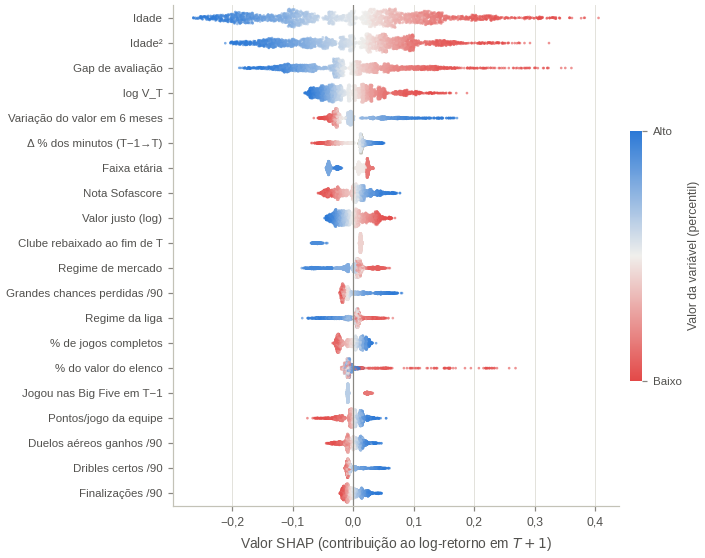

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig02_shap_beeswarm_T2.png


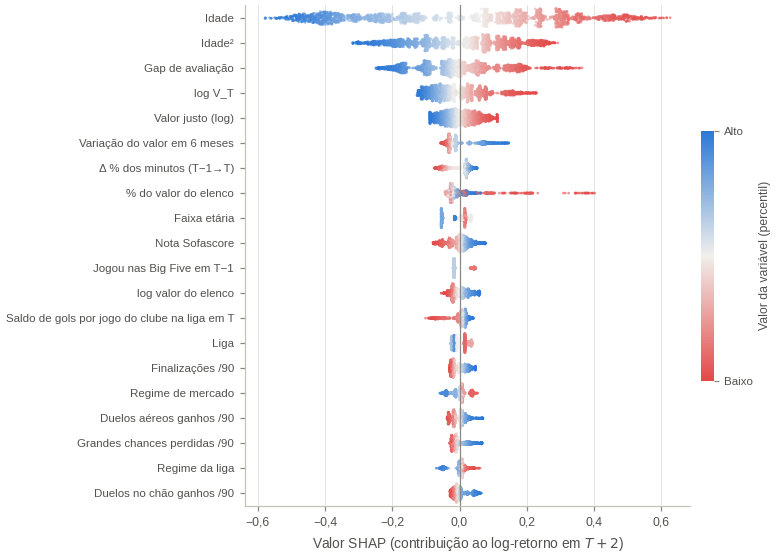

In [4]:
def display_matrix(k: int) -> pd.DataFrame:
    d = frames[k]
    X = pd.DataFrame(index=d.index)
    for c in shap_vals[k].columns:
        X[c] = d[c].astype("category").cat.codes.astype(float) if c in CATEGORICAL else d[c].astype(float)
    return X


for k, name in ((1, "fig01_shap_beeswarm_T1"), (2, "fig02_shap_beeswarm_T2")):
    phi = shap_vals[k]
    top = phi.abs().mean().sort_values(ascending=False).head(20).index.tolist()
    fig, ax = plt.subplots(figsize=pl.figsize(15))
    mappable = pl.beeswarm(ax, phi, display_matrix(k), top, [label(c) for c in top])
    ax.set_xlabel(f"Valor SHAP (contribuição ao log-retorno em $T+{k}$)")
    ax.xaxis.set_major_formatter(pl.br_formatter(1))
    ax.tick_params(axis="y", labelsize=7.5)
    cbar = fig.colorbar(mappable, ax=ax, shrink=0.5, pad=0.02, ticks=[0, 1])
    cbar.ax.set_yticklabels(["Baixo", "Alto"], fontsize=7.5)
    cbar.set_label("Valor da variável (percentil)", fontsize=8)
    cbar.outline.set_visible(False)
    FIG.save(fig, name, f"Valores SHAP das 20 variáveis mais importantes para o log-retorno em T+{k} (ensemble global)",
             note="Cada ponto é um atleta–temporada (amostra de 2.500). Cor: percentil do valor da variável (azul = alto). "
                  "À direita de zero, a variável eleva a valorização prevista.")
    plt.show()

**Leitura.** Participação de cada grupo de variáveis no $|\phi|$ total ($T+1$ / $T+2$):

| Grupo | Participação | Variáveis de destaque |
|---|---|---|
| **Desempenho tático-técnico** | 29% / 25% | nota Sofascore, grandes chances perdidas/90, % de jogos completos, duelos aéreos, dribles, finalizações |
| **Demográfico** | 27% / 34% | idade, idade², faixa etária |
| **Contexto** | 11% / 7% | clube rebaixado, regime de mercado e da liga, pontos/jogo da equipe, liga |
| **Valor justo** | 10% / 10% | gap de avaliação, valor justo |
| **Defasagem** | 9% / 8% | Δ % dos minutos, jogou nas Big Five em T−1, *momentum* |
| **Mercado** | 8% / 10% | $\log V_T$, % do valor do elenco, *ranking* do elenco |
| **Dinâmica de mercado** | 7% / 5% | variação em 6 meses, distância ao pico |

A idade é a variável isolada mais importante, com efeito monotônico: cada ano a mais reduz a
valorização prevista. O **gap de avaliação** é a 3ª variável nos dois horizontes: atletas
subavaliados (gap negativo, em vermelho) recebem contribuição positiva. O $\log V_T$ tem efeito
**negativo**: atletas mais caros se valorizam menos, em termos relativos, o sinal de **reversão de
nível** compatível com a premissa *buy-low*. Entre as variáveis de dinâmica, a **variação do valor nos
últimos seis meses** é a mais forte. O **rebaixamento do clube** ao fim de $T$, variável nova da versão
3, é a 10ª mais importante em $T+1$.

## 3. Como os determinantes mudam ao longo da carreira (12 categorias)

A figura mostra, para cada categoria, a participação de cada grupo de variáveis no total de
$|\phi|$. Ela testa empiricamente a premissa da especificação (§6.4, Khalife et al., 2025): a
importância do potencial e da trajetória deveria cair com a idade, e a do desempenho operacional,
subir.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig03_grupos_por_categoria.png


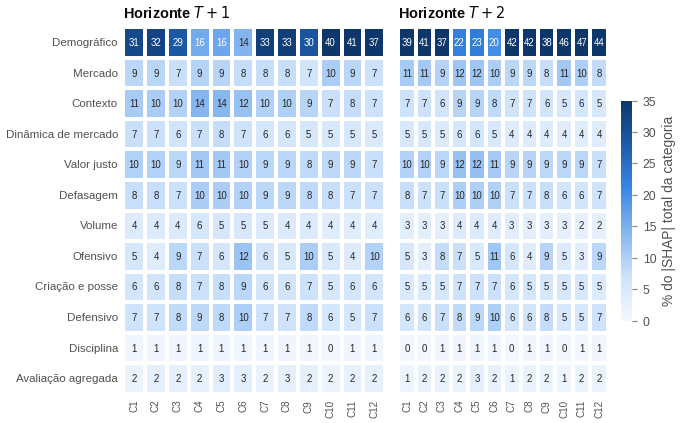

In [5]:
cat_share = {}
for k in HORIZONS:
    phi, d = shap_vals[k], frames[k]
    by_group = phi.abs().T.groupby([group(c) for c in phi.columns]).sum().T
    share = by_group.groupby(d["category"].to_numpy()).mean()
    share = share.div(share.sum(axis=1), axis=0).mul(100).reindex(index=CATEGORIES, columns=GROUP_ORDER).fillna(0)
    cat_share[k] = share.loc[:, share.sum() > 0]   # grupos sem variáveis (fora pela regra de cobertura) saem
save_csv(pd.concat(cat_share, names=["horizonte"]), "tab02_participacao_grupos_por_categoria")

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(11), sharey=True, gridspec_kw={"wspace": 0.05})
for ax, k in zip(axes, HORIZONS):
    d = cat_share[k].T
    d.columns = list(d.columns)
    sns.heatmap(d, annot=pl.annotations(d, 0), fmt="", cmap=pl.SEQUENTIAL, vmin=0, vmax=35, linewidths=1.5,
                linecolor=pl.SURFACE, cbar=ax is axes[1], ax=ax, annot_kws={"fontsize": 6.3},
                cbar_kws={"label": "% do |SHAP| total da categoria", "shrink": 0.6})
    ax.set_title(f"Horizonte $T+{k}$")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(length=0, labelsize=6.5)
    ax.tick_params(axis="y", labelsize=7.5)
    ax.grid(False)
FIG.save(fig, "fig03_grupos_por_categoria",
         "Participação de cada grupo de variáveis na explicação SHAP da valorização, por categoria",
         note="Média de |SHAP| somada por grupo, como % do total de cada categoria (C1–C3: 16–23 anos; C4–C6: 24–28; "
              "C7–C9: 29–32; C10–C12: 33+; em cada trinca, DEF, MEI e ATA). Defasagem inclui o momentum do valor.")
plt.show()

In [6]:
# Equivalente empírico da coluna "SHAP Top 3" da Tabela 6.1 da especificação.
rows = []
for k in HORIZONS:
    phi, d = shap_vals[k], frames[k]
    for c in CATEGORIES:
        mask = (d["category"] == c).to_numpy()
        imp_c = phi[mask].abs().mean().drop(labels=[x for x in CATEGORICAL if x in phi.columns]).sort_values(ascending=False)
        top = imp_c.head(3)
        # direção: correlação de postos entre o valor da variável e sua contribuição
        sign = [np.sign(pd.Series(d.loc[mask, f].to_numpy()).corr(pd.Series(phi.loc[mask, f].to_numpy()), method="spearman"))
                for f in top.index]
        rows.append({"horizonte": f"T+{k}", "categoria": CAT_LABELS[c],
                     **{f"top{i + 1}": f"{label(f)} ({'+' if s > 0 else '−'})" for i, (f, s) in enumerate(zip(top.index, sign))},
                     "top_desempenho": next(label(f) for f in imp_c.index if group(f) in PERFORMANCE_GROUPS)})
top3 = pd.DataFrame(rows)
save_csv(top3, "tab03_top3_shap_por_categoria", index=False)
top3

,horizonte,categoria,top1,top2,top3,top_desempenho
0,T+1,C1 · DEF 16–23,Idade (−),Idade² (−),Gap de avaliação (−),Nota Sofascore
1,T+1,C2 · MEI 16–23,Idade (−),Idade² (−),Gap de avaliação (−),Nota Sofascore
2,T+1,C3 · ATA 16–23,Idade (−),Idade² (−),Gap de avaliação (−),Grandes chances perdidas /90
3,T+1,C4 · DEF 24–28,Gap de avaliação (−),Idade (−),log V_T (−),Nota Sofascore
4,T+1,C5 · MEI 24–28,Gap de avaliação (−),Idade (−),log V_T (−),Nota Sofascore
5,T+1,C6 · ATA 24–28,Gap de avaliação (−),Idade (−),log V_T (−),Grandes chances perdidas /90
6,T+1,C7 · DEF 29–32,Idade (−),Idade² (−),Gap de avaliação (−),Nota Sofascore
7,T+1,C8 · MEI 29–32,Idade (−),Idade² (−),Gap de avaliação (−),Nota Sofascore
8,T+1,C9 · ATA 29–32,Idade (−),Idade² (−),Gap de avaliação (−),Grandes chances perdidas /90
9,T+1,C10 · DEF 33+,Idade (−),Idade² (−),Gap de avaliação (−),Nota Sofascore


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig04_top5_por_categoria.png


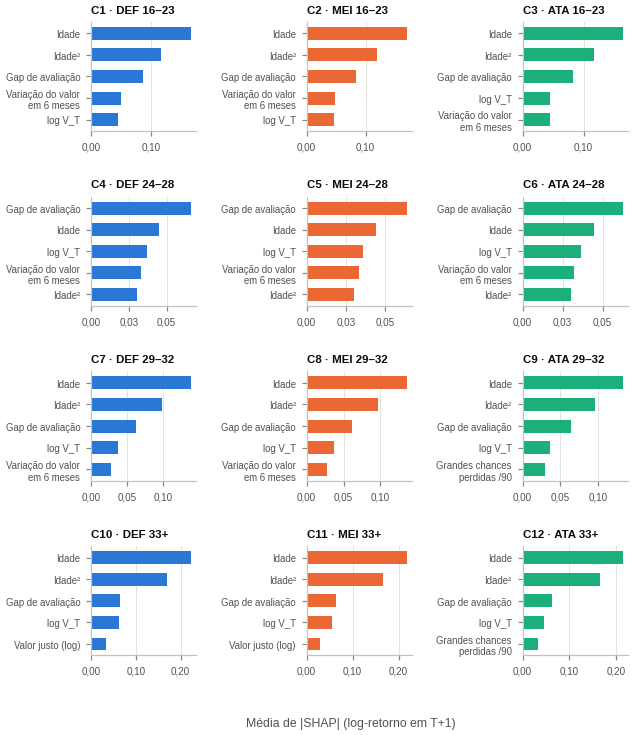

In [7]:
k = 1
phi, d = shap_vals[k], frames[k]
numeric_cols = [c for c in phi.columns if c not in CATEGORICAL]
fig, axes = plt.subplots(4, 3, figsize=pl.figsize(19), gridspec_kw={"hspace": 0.6, "wspace": 1.05})
for ax, c in zip(axes.ravel(), CATEGORIES):
    mask = (d["category"] == c).to_numpy()
    top = phi.loc[mask, numeric_cols].abs().mean().sort_values(ascending=False).head(5)[::-1]
    colors = [pl.POSITION_COLORS[c_pos] for c_pos in [sp.POSITIONS[(int(c[1:]) - 1) % 3]] * len(top)]
    ax.barh(range(len(top)), top.to_numpy(), color=colors, height=0.6)
    ax.set_yticks(range(len(top)), [textwrap.fill(label(f), 18) for f in top.index], fontsize=6.3)
    ax.set_title(CAT_LABELS[c], fontsize=7.5)
    ax.xaxis.set_major_formatter(pl.br_formatter(2))
    ax.tick_params(axis="x", labelsize=6.5)
    ax.grid(axis="y", visible=False)
fig.supxlabel("Média de |SHAP| (log-retorno em T+1)", fontsize=8, color=pl.INK_SECONDARY, y=0.02)
FIG.save(fig, "fig04_top5_por_categoria",
         "As cinco variáveis com maior contribuição média (|SHAP|) para a valorização em T+1, por categoria",
         note="Linhas: faixas etárias (16–23, 24–28, 29–32, 33+). Colunas: defensores, meio-campistas e atacantes.")
plt.show()

**Leitura: o que muda ao longo da carreira.** A Figura 3 permite testar empiricamente a premissa da
especificação (§6.4).

| Faixa ($T+1$; % do $\vert\phi\vert$ de cada categoria) | Demográfico | Desempenho | Valor justo + dinâmica |
|---|---|---|---|
| 16–23 (C1–C3) | 29–32 | 24–32 | 15–17 |
| 24–28 (C4–C6) | **14–16** | **31–40** | 16–19 |
| 29–32 (C7–C9) | 30–33 | 26–33 | 14–15 |
| 33+ (C10–C12) | **37–41** | 21–30 | 12–14 |

- **Peso da idade.** É alto em todas as faixas, exceto no auge. Nos veteranos, a depreciação
  biológica é o fator dominante, e em $T+2$ chega a 44–47%.
- **Desempenho tático-técnico.** O peso é **máximo no auge** (31–40% em C4–C6) e menor nos
  veteranos (21–30%). A diferença entre 24–28 e 33+ é de 10 p.p., com IC estreito (seção 3.1).
- **Posição.** Em todas as faixas, os **atacantes** dependem mais das métricas ofensivas (9–12% do
  total, contra 4–7% de defensores e meio-campistas).
- **Horizonte $T+2$.** Os pesos se deslocam para a idade (34% no agregado), e o desempenho de uma
  única temporada perde importância (18–36%).

*Confronto com a especificação.* A especificação, apoiada em Khalife et al. (2025), previa que a
valoração dos veteranos fosse governada pela produção operacional. Os dados indicam o contrário:
para os atletas de 33 anos ou mais, a idade explica sozinha cerca de 40% da variação prevista, e o
desempenho, uma fração **menor** que no auge. O mercado premia o desempenho sobretudo enquanto ele
sinaliza trajetória futura (24–28 anos). Nos veteranos, nem um bom rendimento compensa a depreciação
esperada.

A tabela de "top 3" (equivalente empírico da Tabela 6.1 da especificação) confirma o padrão: idade,
idade² e gap de avaliação lideram quase todas as categorias. Nos atletas de 24–28 anos, em $T+1$, o
gap é a variável mais importante, à frente da idade, e o $\log V_T$ aparece em 3º lugar.

### 3.1 Intervalos de confiança das participações (H5)

A diferença de pesos entre faixas etárias só sustenta conclusões se for maior que a incerteza
amostral. As participações de cada grupo de variáveis no $|\phi|$ total são reestimadas em 1.000
reamostragens de clusters (clube × temporada) dentro de cada faixa. **H5** prevê que o desempenho
tático-técnico pese mais no auge (24–28) que entre os veteranos (33+).

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig03b_participacao_faixa_ic95.png


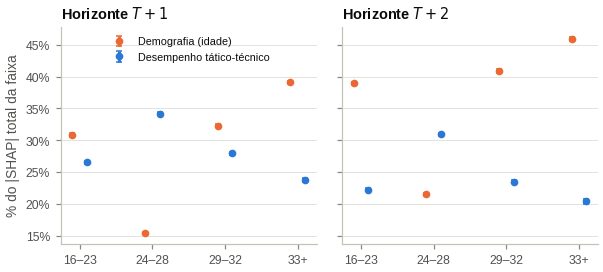

,horizonte,dif_desempenho_auge_menos_veteranos_pp,ic95_inf,ic95_sup
0,T+1,10.430,10.030,10.810
1,T+2,10.500,10.120,10.880


In [8]:
PERF_BLOCK = "Desempenho tático-técnico"
h5_rows, h5_diff = [], []
for k in HORIZONS:
    phi, d = shap_vals[k], frames[k]
    block_of = {c: PERF_BLOCK if group(c) in PERFORMANCE_GROUPS else group(c) for c in phi.columns}
    bands, codes = d["age_band"].astype(str).reset_index(drop=True), md.cluster_codes(d)
    ci = it.group_share_bootstrap(phi, block_of, bands, codes, n_boot=1000)
    h5_rows.append(ci.assign(horizonte=f"T+{k}"))
    # diferença auge − veteranos na participação do desempenho, com IC por bootstrap de clusters
    perf = phi[[c for c, b in block_of.items() if b == PERF_BLOCK]].abs().sum(axis=1).to_numpy()
    tot = phi.abs().sum(axis=1).to_numpy()
    band = bands.to_numpy()
    clusters = np.unique(codes)
    members = {c: np.flatnonzero(codes == c) for c in clusters}
    rng = np.random.default_rng(42)

    def gap(idx: np.ndarray) -> float:
        b = band[idx]
        return (perf[idx][b == "24–28"].sum() / tot[idx][b == "24–28"].sum()
                - perf[idx][b == "33+"].sum() / tot[idx][b == "33+"].sum()) * 100

    draws = [gap(np.concatenate([members[c] for c in rng.choice(clusters, len(clusters))])) for _ in range(1000)]
    h5_diff.append({"horizonte": f"T+{k}", "dif_desempenho_auge_menos_veteranos_pp": gap(np.arange(len(band))),
                    "ic95_inf": np.quantile(draws, 0.025), "ic95_sup": np.quantile(draws, 0.975)})
h5 = pd.concat(h5_rows)
h5_diff = pd.DataFrame(h5_diff)
save_csv(h5, "tab02b_participacao_grupos_faixa_ic95", index=False)
save_csv(h5_diff, "tab02c_h5_desempenho_auge_vs_veteranos", index=False)

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(6.5), sharey=True, gridspec_kw={"wspace": 0.1})
for ax, k in zip(axes, HORIZONS):
    d = h5[h5["horizonte"] == f"T+{k}"].set_index(["grupo", "nivel"])
    for offset, (grp, color, name) in zip((-0.1, 0.1), (("Demográfico", pl.ORANGE, "Demografia (idade)"),
                                                         (PERF_BLOCK, pl.BLUE, PERF_BLOCK))):
        r = d.loc[grp].reindex(BANDS)
        ax.errorbar(np.arange(len(BANDS)) + offset, r["participacao_pct"],
                    yerr=[r["participacao_pct"] - r["ic95_inf"], r["ic95_sup"] - r["participacao_pct"]],
                    fmt="o", color=color, markersize=4, capsize=2, label=name)
    ax.set_xticks(range(len(BANDS)), BANDS)
    ax.yaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_title(f"Horizonte $T+{k}$")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% do |SHAP| total da faixa")
axes[0].legend(loc="upper center", fontsize=7)
FIG.save(fig, "fig03b_participacao_faixa_ic95",
         "Participação da idade e do desempenho tático-técnico na explicação SHAP, por faixa etária",
         note="Hastes: IC de 95% por bootstrap de clubes × temporada (1.000 reamostragens).")
plt.show()
display(h5_diff.round(2))

**Leitura (H5).** A participação do desempenho tático-técnico é maior no auge (24–28: 34% em $T+1$ e
31% em $T+2$) do que entre os veteranos (33+: 24% e 20%). A diferença é de **10,4 p.p.** (IC 95%:
10,0–10,8) em $T+1$ e de **10,5 p.p.** (10,1–10,9) em $T+2$: a **H5 é sustentada** pelo critério
pré-registrado. A idade tem o padrão inverso: 16% no auge contra 39% nos veteranos ($T+1$). O IC é
condicional ao modelo final; a seção 6 refaz o cálculo nos modelos de cada dobra.

## 4. Variáveis tático-técnicas mais determinantes, por posição

Atende ao objetivo da especificação de identificar as métricas de desempenho de maior peso na
valorização futura. Ficam de fora a idade, o mercado, a dinâmica de reavaliações e o valor justo.
A direção (+/−) é o sinal da correlação de postos entre o valor da métrica e sua contribuição
SHAP: (+) significa que mais da métrica eleva a valorização prevista.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig05_desempenho_por_posicao.png


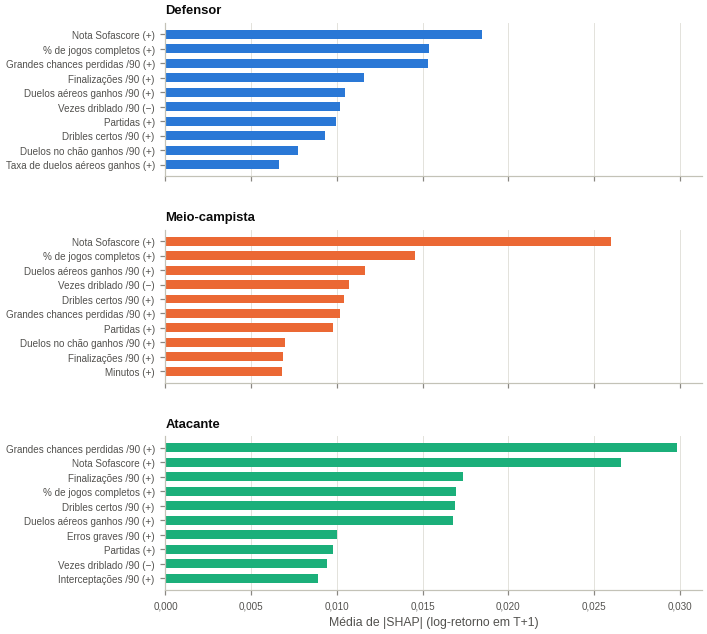

Participação do desempenho tático-técnico no |SHAP| total: T+1: 29.2%, T+2: 25.3%


In [9]:
perf_rows = []
fig, axes = plt.subplots(3, 1, figsize=pl.figsize(17), sharex=True, gridspec_kw={"hspace": 0.35})
for ax, pos in zip(axes, POS):
    k = 1
    phi, d = shap_vals[k], frames[k]
    mask = (d["position_group"] == pos).to_numpy()
    cols = [c for c in phi.columns if c not in CATEGORICAL and group(c) in PERFORMANCE_GROUPS]
    top = phi.loc[mask, cols].abs().mean().sort_values(ascending=False).head(10)
    signs = [np.sign(pd.Series(d.loc[mask, f].to_numpy()).corr(pd.Series(phi.loc[mask, f].to_numpy()), method="spearman"))
             for f in top.index]
    for f, v, s in zip(top.index, top.to_numpy(), signs):
        perf_rows.append({"posicao": sp.POSITION_LABELS[pos], "variavel": label(f), "grupo": group(f),
                          "mean_abs_shap_T1": v, "direcao": "+" if s > 0 else "−"})
    top, signs = top[::-1], signs[::-1]
    ax.barh(range(len(top)), top.to_numpy(), color=pl.POSITION_COLORS[pos], height=0.62)
    ax.set_yticks(range(len(top)), [f"{label(f)} ({'+' if s > 0 else '−'})" for f, s in zip(top.index, signs)], fontsize=6.5)
    ax.set_title(sp.POSITION_LABELS[pos], fontsize=8.5)
    ax.xaxis.set_major_formatter(pl.br_formatter(3))
    ax.tick_params(axis="x", labelsize=6.5)
    ax.grid(axis="y", visible=False)
axes[-1].set_xlabel("Média de |SHAP| (log-retorno em T+1)", fontsize=8, color=pl.INK_SECONDARY)
perf_tab = pd.DataFrame(perf_rows)
save_csv(perf_tab, "tab04_top_desempenho_por_posicao", index=False)
FIG.save(fig, "fig05_desempenho_por_posicao",
         "As dez métricas tático-técnicas com maior contribuição para a valorização em T+1, por posição",
         note="(+): valores altos da métrica elevam a valorização prevista; (−): reduzem.")
plt.show()
share_perf = {k: shap_vals[k].abs().T.groupby([group(c) for c in shap_vals[k].columns]).sum().T.sum()
              .pipe(lambda s: s[PERFORMANCE_GROUPS].sum() / s.sum() * 100) for k in HORIZONS}
print("Participação do desempenho tático-técnico no |SHAP| total: "
      + ", ".join(f"T+{k}: {v:.1f}%" for k, v in share_perf.items()))

**Leitura: as variáveis tático-técnicas mais determinantes.** Dentro do vetor de desempenho, que
responde por 29% da explicação em $T+1$, duas famílias se destacam:

1. **Avaliação e regularidade**, nas três posições: nota média do Sofascore, % de jogos completos e
   partidas, todas com efeito positivo. O mercado valoriza quem se firma como titular e é bem avaliado.
2. **Produção específica da posição:**
   - **atacantes:** grandes chances perdidas/90, finalizações/90, dribles certos/90 e duelos aéreos
     ganhos/90;
   - **meio-campistas:** duelos aéreos ganhos, dribles certos e grandes chances perdidas, com "vezes
     driblado" em efeito negativo;
   - **defensores:** grandes chances perdidas e finalizações (participação ofensiva), duelos aéreos e
     no chão ganhos, com "vezes driblado" em efeito negativo.

"Grandes chances perdidas/90" com efeito positivo mede **presença em situações claras de gol**, e não
ineficiência: condicionada às finalizações e à nota, é a participação nessas chances que o mercado
premia. Efeitos de variáveis correlacionadas se dividem entre elas e não devem ser lidos
isoladamente; o encolhimento das taxas aumentou essas correlações.

*Limitação.* As métricas que a especificação tratava como centrais (passes progressivos,
conduções progressivas, SCA, duelos aéreos) foram aproximadas por *proxies* do Sofascore e do
Understat, porque o FBref deixou de publicar os dados Opta. As *proxies* de criação têm peso
moderado.

## 5. Gráficos de dependência

Os gráficos de dependência mostram como a contribuição de uma variável varia com o seu valor. Isso
revela não linearidades e, pela cor, interações com a faixa etária.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig06_dependencia_shap.png


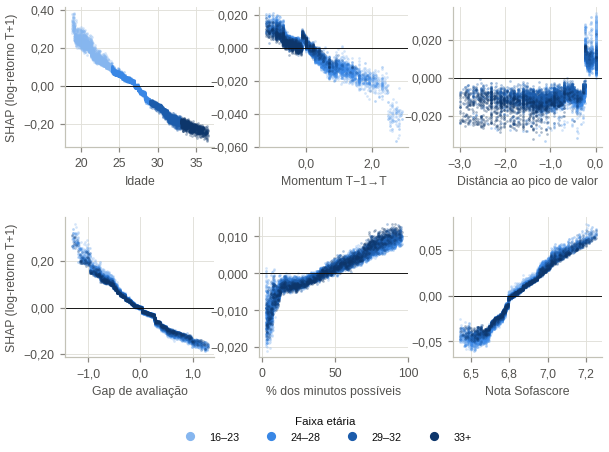

In [10]:
k = 1
phi, d = shap_vals[k], frames[k]
dep_vars = ["age", "log_return_lag1", "mkt_peak_gap", "value_gap_T", "minutes_share_pct", "sofascore_rating"]
fig, axes = plt.subplots(2, 3, figsize=pl.figsize(10.5), gridspec_kw={"hspace": 0.5, "wspace": 0.3})
band_colors = dict(zip(BANDS, pl.AGE_BAND_COLORS))
for ax, f in zip(axes.ravel(), dep_vars):
    x = d[f].astype(float)
    lo, hi = x.quantile([0.01, 0.99])
    for band in BANDS:
        m = (d["age_band"] == band).to_numpy() & x.between(lo, hi).to_numpy()
        ax.scatter(x[m], phi.loc[m, f], s=3, alpha=0.35, color=band_colors[band], linewidths=0, label=band)
    ax.axhline(0, color=pl.INK, linewidth=0.6)
    ax.set_xlabel(label(f), fontsize=8)
    span = phi[f].abs().quantile(0.99)
    ax.yaxis.set_major_formatter(pl.br_formatter(3 if span < 0.05 else 2))
    ax.xaxis.set_major_formatter(pl.br_formatter(1 if f in ("log_return_lag1", "mkt_peak_gap", "value_gap_T", "sofascore_rating") else 0))
for ax in axes[:, 0]:
    ax.set_ylabel("SHAP (log-retorno T+1)", fontsize=8)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, markersize=5) for c in pl.AGE_BAND_COLORS]
fig.legend(handles, BANDS, title="Faixa etária", loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=7, title_fontsize=7.5)
FIG.save(fig, "fig06_dependencia_shap",
         "Gráficos de dependência SHAP das principais variáveis para a valorização em T+1",
         note="Cada ponto é um atleta–temporada; extremos (1% de cada lado) omitidos.")
plt.show()

**Leitura.** Os gráficos de dependência mostram seis relações:
- **Idade:** efeito praticamente linear e decrescente, de cerca de +0,30 aos 19 anos a −0,25 aos 36,
  com cruzamento do zero por volta dos 27 anos.
- **Gap de avaliação:** efeito monotônico e **assimétrico**. Os mais subavaliados (gap ≈ −1,2)
  recebem até +0,30 (≈ +35%), e os sobreavaliados (gap ≈ +1,2), cerca de −0,17 (≈ −16%). A correção
  de preço é mais forte para quem está barato do que para quem está caro.
- **Nota Sofascore:** relação em forma de S, de −0,05 (nota 6,5) a +0,065 (nota 7,25), cerca de 12
  p.p. de valorização entre os extremos.
- **% dos minutos possíveis:** relação positiva, mas pequena (de −0,01 a +0,01), com queda abrupta
  abaixo de 10% dos minutos. Com o encolhimento, a minutagem atua sobretudo pela confiabilidade das
  taxas.
- ***Momentum* anual (T−1→T):** contribuição pequena e decrescente. Altas passadas muito grandes
  (log-retorno > 2) recebem −0,02 a −0,05, sinal de **reversão após saltos extremos**.
- **Distância ao pico:** atletas no próprio pico recebem efeito positivo (+0,01 a +0,03); os que
  estão abaixo dele, negativo, sem expectativa de recuperação.

## 6. Estabilidade das explicações entre as dobras

O modelo final é treinado com todas as temporadas. Para saber se as explicações dependem de uma
temporada específica, os componentes do *ensemble* são reajustados no treino de **cada dobra** da janela
expandida, com os mesmos hiperparâmetros, e explicam só a temporada de teste daquela dobra, isto é,
as previsões fora da amostra que eles mesmos geraram. A tabela traz o $\tau$ de Kendall entre os
rankings das 20 variáveis mais importantes de cada par de dobras e a faixa da participação de cada
grupo entre as dobras.

O mesmo conjunto de modelos testa a **H5 com a incerteza do ajuste**: o IC da seção 3.1 é condicional
ao modelo final, e a diferença de participação do desempenho entre o auge (24–28) e os veteranos
(33+) é recalculada no modelo de cada dobra (`tab10c`).

           mean   min   max
horizonte                  
T+1       0.636 0.432 0.821
T+2       0.739 0.642 0.863


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig11_estabilidade_shap_dobras.png


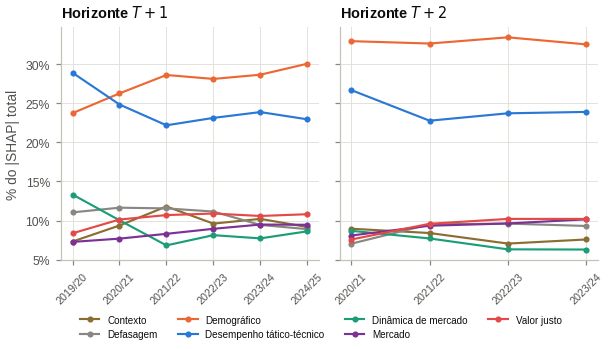

In [11]:
SPECS = md.model_specs(5, 5)          # só os construtores dos algoritmos; não há otimização aqui
fold_shap = {}
for k in HORIZONS:
    entry = manifest["horizons"][f"T{k}"]
    for i, f in enumerate(entry["folds"], 1):
        comps = {}
        for m, info in entry["global"].items():
            task = md.Task(k, "global", m, tuple(info["numeric"]), tuple(info["categorical"]))
            comps[m] = md.fit_final(SPECS[m], info["params"], task, panel, seasons=f["train"])
        test = panel[(panel["season"] == f["test"]) & (panel[f"has_target_T{k}"] == 1)]
        fm = it.fold_model(k, comps)
        phi, base = it.ensemble_shap(fm, test)
        fold_shap[(k, i)] = {"phi": it.collapse_dummies(phi, CATEGORICAL), "base": base, "data": test,
                             "pred": fm.predict(test), "season": f["test"]}

stab_rows, fold_share_rows = [], []
for k in HORIZONS:
    keys = sorted(i for (h, i) in fold_shap if h == k)
    imps = {fold_shap[(k, i)]["season"]: fold_shap[(k, i)]["phi"].abs().mean() for i in keys}
    stab_rows.append(it.importance_stability(imps, top=20).assign(horizonte=f"T+{k}"))
    for i in keys:
        phi = fold_shap[(k, i)]["phi"]
        sh = it.group_shares(phi, {c: group(c) for c in phi.columns})
        fold_share_rows += [{"horizonte": f"T+{k}", "temporada_teste": sp.season_label(fold_shap[(k, i)]["season"]),
                             "grupo": g, "participacao_pct": v} for g, v in sh.items()]
stab = pd.concat(stab_rows)
fold_shares = pd.DataFrame(fold_share_rows)
save_csv(stab, "tab10_estabilidade_shap_kendall", index=False)
save_csv(fold_shares, "tab10b_participacao_grupos_por_dobra", index=False)
print(stab.groupby("horizonte")["tau_kendall"].describe()[["mean", "min", "max"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(7), sharey=True, gridspec_kw={"wspace": 0.08})
BLOCK_COLORS = {"Desempenho tático-técnico": pl.BLUE, "Demográfico": pl.ORANGE, "Mercado": "#7b3294",
                "Contexto": "#8c6d31", "Dinâmica de mercado": "#1b9e77", "Valor justo": pl.RED, "Defasagem": pl.INK_MUTED}
for ax, k in zip(axes, HORIZONS):
    d = fold_shares[fold_shares["horizonte"] == f"T+{k}"]
    agg = d.assign(bloco=d["grupo"].map(lambda g: "Desempenho tático-técnico" if g in PERFORMANCE_GROUPS else g))
    agg = agg.groupby(["temporada_teste", "bloco"])["participacao_pct"].sum().unstack()
    for col in agg.columns:
        ax.plot(range(len(agg)), agg[col], marker="o", markersize=3, linewidth=1.4, label=col,
                color=BLOCK_COLORS.get(col, pl.NEUTRAL))
    ax.set_xticks(range(len(agg)), agg.index, rotation=45, fontsize=7)
    ax.yaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_title(f"Horizonte $T+{k}$")
axes[0].set_ylabel("% do |SHAP| total")
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=4, fontsize=6.5)
FIG.save(fig, "fig11_estabilidade_shap_dobras",
         "Participação dos grupos de variáveis na explicação SHAP do modelo de cada dobra, por temporada de teste",
         note="Modelos reajustados no treino de cada dobra, com os hiperparâmetros do modelo final; SHAP na temporada de teste.")
plt.show()

In [12]:
# H5 com a incerteza do ajuste: diferença auge − veteranos no modelo de cada dobra
h5_fold = []
for (k, i), v in sorted(fold_shap.items()):
    phi, band = v["phi"], v["data"]["age_band"].astype(str).to_numpy()
    perf = phi[[c for c in phi.columns if group(c) in PERFORMANCE_GROUPS]].abs().sum(axis=1).to_numpy()
    tot = phi.abs().sum(axis=1).to_numpy()
    share = {b: perf[band == b].sum() / tot[band == b].sum() * 100 for b in ("24–28", "33+")}
    h5_fold.append({"horizonte": f"T+{k}", "temporada_teste": sp.season_label(v["season"]),
                    "desempenho_24_28_pct": share["24–28"], "desempenho_33_pct": share["33+"],
                    "dif_pp": share["24–28"] - share["33+"]})
h5_fold = pd.DataFrame(h5_fold)
save_csv(h5_fold, "tab10c_h5_por_dobra", index=False)
display(h5_fold.round(1), h5_fold.groupby("horizonte")["dif_pp"].agg(["min", "max", "mean"]).round(1))

,horizonte,temporada_teste,desempenho_24_28_pct,desempenho_33_pct,dif_pp
0,T+1,2019/20,33.600,24.400,9.300
1,T+1,2020/21,29.900,20.900,9.000
2,T+1,2021/22,25.900,19.100,6.800
3,T+1,2022/23,28.000,18.800,9.200
4,T+1,2023/24,28.800,19.900,8.900
5,T+1,2024/25,28.300,18.800,9.500
6,T+2,2020/21,32.200,21.900,10.300
7,T+2,2021/22,27.200,18.200,9.000
8,T+2,2022/23,29.300,18.500,10.700
9,T+2,2023/24,29.300,19.700,9.600


,min,max,mean
horizonte,,,
T+1,6.800,9.500,8.800
T+2,9.000,10.700,9.900


**Leitura.** Os modelos das dobras apoiam-se nas mesmas variáveis: o $\tau$ de Kendall entre os
rankings das 20 mais importantes é de 0,64 em média em $T+1$ (0,43–0,82) e de 0,74 em $T+2$
(0,64–0,86). O modelo da 1ª dobra, treinado só com 2018/19, é o mais diferente (0,43–0,57); entre dobras
consecutivas a partir da 2ª, o $\tau$ vai de 0,72 a 0,82. A diferença de participação do desempenho entre
o auge e os veteranos é positiva em **todos** os modelos de dobra: 6,8 a 9,5 p.p. em $T+1$ e 9,0 a 10,7
p.p. em $T+2$. A H5 não depende de uma temporada nem do modelo final.

## 7. Explicações individuais (*waterfall*)

Para cada faixa etária, o gráfico decompõe a previsão do atleta com maior valorização esperada no teste
final de $T+1$. A decomposição usa o **modelo da própria dobra do teste**, o mesmo que gerou a previsão
fora da amostra exibida no título; a igualdade entre a soma das contribuições e essa previsão é
verificada numericamente. O título traz o valor em $T$, o $\Delta V\%$ previsto (mediano e esperado), o
intervalo de 80% e o $\Delta V\%$ realizado.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig07_waterfall_exemplos.png


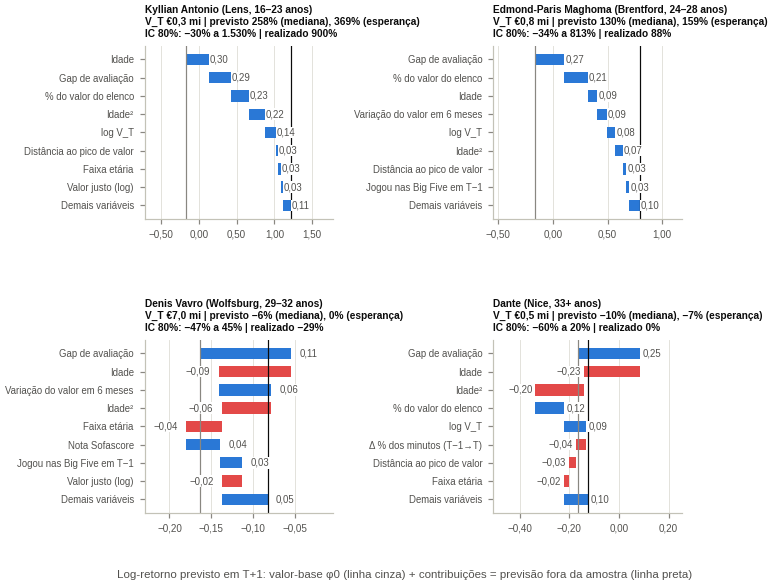

,fb_player,fb_team,age_band,value_T,dv_pct_pred_median,dv_pct_pred_mean,dv_pct_true
0,Kyllian Antonio,Lens,16–23,"300,000.000",257.703,369.335,900.000
1,Edmond-Paris Maghoma,Brentford,24–28,"800,000.000",130.464,158.817,87.500
2,Denis Vavro,Wolfsburg,29–32,"7,000,000.000",-6.427,0.160,-28.571
3,Dante,Nice,33+,"500,000.000",-10.305,-6.835,0.000


In [13]:
k = 1
hold_fold = max(i for (h, i) in fold_shap if h == k)
fs_h = fold_shap[(k, hold_fold)]
assert fs_h["season"] == HOLDOUT[k]
hold = best[(best["horizon"] == k) & best["is_holdout"] & best["has_target"]].copy()
band_col = "age_band"
picks = hold.sort_values("dv_pct_pred_mean", ascending=False).groupby(band_col).head(1)
picks = picks.set_index(band_col).reindex(BANDS).reset_index()
pos = pd.Series(range(len(fs_h["data"])), index=pd.MultiIndex.from_frame(fs_h["data"][["season", "fbref_player_id"]]))
# o modelo da dobra reproduz exatamente o componente global das previsões fora da amostra do notebook 04
chk = hold.merge(fs_h["data"][["season", "fbref_player_id"]].assign(fold_pred=fs_h["pred"]), on=["season", "fbref_player_id"])
assert np.allclose(chk["fold_pred"], chk["y_pred_global"], atol=1e-6), "modelo da dobra difere das previsões do notebook 04"

fig, axes = plt.subplots(2, 2, figsize=pl.figsize(14), gridspec_kw={"hspace": 0.7, "wspace": 0.85})
wf_rows = []
for ax, (_, r) in zip(axes.ravel(), picks.iterrows()):
    j = pos[(r["season"], r["fbref_player_id"])]
    contrib = fs_h["phi"].iloc[j]
    assert abs(fs_h["base"] + contrib.sum() - r["y_pred_global"]) < 1e-6
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(8)
    items = list(top.items()) + [("Demais variáveis", contrib.drop(top.index).sum())]
    if abs(r["y_pred"] - r["y_pred_global"]) > 1e-9:   # arquitetura final com segmentos: ajuste do pooling
        items.append(("Ajuste do segmento (pooling)", r["y_pred"] - r["y_pred_global"]))
    start = fs_h["base"]
    path_ = np.cumsum([start] + [v for _, v in items])
    lo, hi = path_.min(), path_.max()
    pad = (hi - lo) * 0.4   # espaço para os rótulos fora das barras
    for jj, (name, v) in enumerate(items):
        ax.barh(jj, v, left=start, color=pl.BLUE if v >= 0 else pl.RED, height=0.62)
        ax.text(start + v + (0.01 if v >= 0 else -0.01), jj, pl.br(v, 2), va="center", ha="left" if v >= 0 else "right",
                fontsize=6.3, color=pl.INK_SECONDARY, zorder=4,
                bbox={"boxstyle": "square,pad=0.08", "facecolor": pl.SURFACE, "edgecolor": "none"})
        start += v
        wf_rows.append({"atleta": r["fb_player"], "variavel": name if name in ("Demais variáveis", "Ajuste do segmento (pooling)")
                        else label(name), "shap": v})
    ax.axvline(fs_h["base"], color=pl.INK_MUTED, linewidth=0.8, zorder=1.5)
    ax.axvline(start, color=pl.INK, linewidth=0.8, zorder=1.5)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_yticks(range(len(items)), [n if n in ("Demais variáveis", "Ajuste do segmento (pooling)") else label(n)
                                      for n, _ in items], fontsize=6.3)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(pl.br_formatter(2))
    ax.tick_params(axis="x", labelsize=6.5)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{r['fb_player']} ({r['fb_team']}, {r[band_col]} anos)\n"
                 f"V_T €{pl.br(r['value_T'] / 1e6, 1)} mi | previsto {pl.br_pct(r['dv_pct_pred_median'], 0)} (mediana), "
                 f"{pl.br_pct(r['dv_pct_pred_mean'], 0)} (esperança)\n"
                 f"IC 80%: {pl.br_pct(np.expm1(r['q10_conf']) * 100, 0)} a {pl.br_pct(np.expm1(r['q90_conf']) * 100, 0)} | "
                 f"realizado {pl.br_pct(r['dv_pct_true'], 0)}", fontsize=6.6, loc="left")
fig.supxlabel("Log-retorno previsto em T+1: valor-base φ0 (linha cinza) + contribuições = previsão fora da amostra (linha preta)",
              fontsize=7.5, color=pl.INK_SECONDARY, y=0.0)
save_csv(pd.DataFrame(wf_rows), "tab05_waterfall_exemplos", index=False)
FIG.save(fig, "fig07_waterfall_exemplos",
         f"Decomposição SHAP da previsão de valorização em T+1 para o atleta de maior valorização esperada em cada faixa etária "
         f"({sp.season_label(HOLDOUT[1])})",
         note="Modelo da dobra do teste final, o mesmo que gerou a previsão. Valores em log-retorno.")
plt.show()
picks[["fb_player", "fb_team", band_col, "value_T", "dv_pct_pred_median", "dv_pct_pred_mean", "dv_pct_true"]]

**Leitura.** Os quatro casos ilustram como a mesma estrutura gera previsões opostas (teste de 2024/25):

- **Kyllian Antonio** (Lens, 16–23 anos, € 0,3 mi): previsão de +258% (mediana) e +369% (esperança).
  Ela vem da idade (+0,30, mais +0,22 da idade²), do gap de avaliação favorável (+0,29), da participação
  mínima no valor do elenco (+0,23) e do $V_T$ baixo (+0,14). Ele se valorizou 900%, dentro do intervalo
  de 80% (−30% a +1.530%).
- **Edmond-Paris Maghoma** (Brentford, 24–28 anos, € 0,8 mi): previsão de +130% a +159%, puxada pelo gap
  (+0,27) e pela participação no elenco (+0,21). Realização de +88%, dentro do intervalo (−34% a +814%).
- **Denis Vavro** (Wolfsburg, 29–32 anos, € 7 mi) e **Dante** (Nice, 33+): os melhores casos dessas faixas
  têm previsão de −6% a 0% e de −10% a −7%. O gap favorável (+0,11 e +0,25) não compensa a idade (−0,09 e
  −0,23, mais −0,06 e −0,20 da idade²). As realizações (−29% e 0%) ficaram dentro dos intervalos.

As variáveis de desempenho aparecem pouco entre as maiores contribuições individuais (só a nota
Sofascore de Vavro, +0,04): elas agem sobretudo pelo valor justo e pelo gap, que as resumem. Para o
*scout*, o *waterfall* responde **por que** o modelo recomenda um atleta e permite distinguir uma aposta
sustentada por desempenho de uma sustentada só por idade e preço.

## 8. Gap de avaliação e valorização realizada (H3)

A premissa *buy-low* diz que atletas mais baratos do que o desempenho sugere se valorizam mais. O teste
usa o gap de avaliação em $T$ (notebook 03) e o log-retorno **realizado**, por quintil do gap, nas dobras
de desenvolvimento e no teste final. O $\rho$ parcial controla idade, idade² e $\log V_T$, porque o gap se
correlaciona com o nível de preço.

In [14]:
def residual_ranks(x: pd.Series, controls: pd.DataFrame) -> np.ndarray:
    design = np.column_stack([np.ones(len(x)), controls.to_numpy(float)])
    r = x.rank().to_numpy(float)
    beta, *_ = np.linalg.lstsq(design, r, rcond=None)
    return r - design @ beta


gap_rows, rho_rows = [], []
for k in HORIZONS:
    base_k = best[(best["horizon"] == k) & best["has_target"]].merge(
        panel[["season", "fbref_player_id", "value_gap_T", "age", "log_value_T"]], on=["season", "fbref_player_id"])
    for scope, d in (("desenvolvimento", base_k[~base_k["is_holdout"]]), ("teste final", base_k[base_k["is_holdout"]])):
        d = d.dropna(subset=["value_gap_T"]).copy()
        d["quintil"] = d.groupby("season")["value_gap_T"].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False) + 1)
        for q, g in d.groupby("quintil"):
            ci = md.cluster_bootstrap(g, lambda x: float(np.expm1(x["y_true"].median()) * 100), n_boot=500)
            gap_rows.append({"horizonte": f"T+{k}", "avaliacao": scope, "quintil_gap": int(q), "n": len(g),
                             "variacao_mediana_pct": ci["estimate"], "ic95_inf": ci["ci_low"], "ic95_sup": ci["ci_high"],
                             "pct_valorizou": (g["y_true"] > 0).mean() * 100})
        ctrl = pd.concat([d["age"], d["age"] ** 2, d["log_value_T"]], axis=1)
        rho = np.corrcoef(residual_ranks(d["value_gap_T"], ctrl), residual_ranks(d["y_true"], ctrl))[0, 1]
        rho_rows.append({"horizonte": f"T+{k}", "avaliacao": scope, "n": len(d),
                         "rho_spearman": d["value_gap_T"].corr(d["y_true"], method="spearman"), "rho_parcial": rho})
gap_tab, rho_tab = pd.DataFrame(gap_rows), pd.DataFrame(rho_rows)
save_csv(gap_tab, "tab11_h3_gap_quintis", index=False)
save_csv(rho_tab, "tab11b_h3_gap_correlacao", index=False)
display(rho_tab.round(3), gap_tab.pivot_table(index=["horizonte", "avaliacao"], columns="quintil_gap",
                                              values="variacao_mediana_pct").round(1))

,horizonte,avaliacao,n,rho_spearman,rho_parcial
0,T+1,desenvolvimento,9682,-0.150,-0.181
1,T+1,teste final,1952,-0.149,-0.204
2,T+2,desenvolvimento,5709,-0.140,-0.156
3,T+2,teste final,1879,-0.108,-0.149


quintil_gap                     1       2       3       4       5
horizonte avaliacao                                              
T+1       desenvolvimento  -5.700 -20.000 -20.000 -20.000 -25.000
          teste final      -5.900 -20.000 -20.000 -25.000 -20.000
T+2       desenvolvimento -25.000 -36.900 -37.500 -40.000 -46.700
          teste final     -25.000 -40.000 -41.700 -41.700 -38.500

**Leitura (H3).** O gap ordena a valorização realizada. No teste final, o quintil mais subavaliado tem
mediana de **−5,9%** em $T+1$ (35% se valorizaram), contra −20,0% do mais sobreavaliado (23%). Em $T+2$, é
−25,0% (35%) contra −38,5% (28%). O ganho concentra-se no quintil mais barato: nos demais, a mediana fica
entre −20% e −25% em $T+1$. A correlação parcial entre o gap e o log-retorno, controlada por idade, idade² e
$\log V_T$, é negativa nos dois horizontes: −0,18 (desenvolvimento) e −0,20 (teste) em $T+1$; −0,16 e −0,15
em $T+2$. Pelo critério pré-registrado (ICs disjuntos), a **H3 é sustentada em $T+1$**. Em $T+2$, os ICs se
tocam em −33,3% e o critério estrito não é atendido.

## 9. Simulação de recrutamento *buy-low / sell-high* (H4)

*Backtest* fora da amostra. Em cada temporada de teste, um clube compra uma carteira de atletas e a
avalia em $T+k$. As previsões são as fora da amostra do notebook 04: o modelo nunca viu a temporada em que
decide. Três mudanças em relação à versão 2 tornam o *backtest* mais realista:

1. **Intenção de tratar.** Os candidatos incluem os atletas que depois saem da base (sem $V_{T+k}$:
   aposentadoria ou liga não avaliada). Eles entram como **excluídos** (o *backtest* da v2), valendo
   **zero** (limite pessimista) ou pelo **último valor publicado** (limite otimista).
2. **Custos de transação.** Compra por $V_T(1+c_b)$ e venda por $V_{T+k}(1-c_v)$, com $c_b \in \{0; 10\%;
   25\%\}$ (ágio sobre o valor de mercado, comissões) e $c_v \in \{0; 10\%\}$.
3. **Inferência entre temporadas.** Teste do sinal: sob a hipótese nula, a estratégia vence o acaso em
   cada temporada com probabilidade 1/2.

**Cenário principal:** $c_b = c_v = 10\%$ e atletas sem $V_{T+k}$ valendo zero.

| Estratégia | Regra |
|---|---|
| **Modelo** | maior retorno esperado previsto (camada de magnitude) |
| **Modelo prudente** | maior cenário pessimista previsto (P10 do intervalo de 80%) |
| ***Momentum*** | maior valorização passada (log-retorno T−1→T), sem modelo |
| **Mais jovens** | os 10% de menor idade (referência acrescentada depois da revelação do teste; seção 9.2) |
| **Juventude** | atletas de 16–23 anos ao acaso (2.000 sorteios) |
| **Aleatória** | atletas ao acaso (2.000 sorteios) |

In [15]:
rng = np.random.default_rng(42)
N_DRAWS = 2000
COSTS = [(0.0, 0.0), (0.10, 0.10), (0.25, 0.10)]
MISSING = list(it.MISSING_OUTCOMES)
MAIN = {"buy_cost": 0.10, "sell_cost": 0.10, "missing": "zero"}
sim = best.merge(panel[["season", "fbref_player_id", "log_return_lag1", "age"]], on=["season", "fbref_player_id"], how="left")
band_col = "age_band"
PRICE_BAND = (2e6, 15e6)  # mercado-alvo de um clube médio: exclui promessas da base e atletas caros
UNIVERSES = {"Todos os candidatos": lambda d: d, "Faixa de € 2–15 mi": lambda d: d[d["value_T"].between(*PRICE_BAND)]}
rows = []
for (universe, flt), k in [(u, k) for u in UNIVERSES.items() for k in HORIZONS]:
    for season, cands in flt(sim[sim["horizon"] == k]).groupby("season"):
        cands = cands.reset_index(drop=True)
        n = max(1, len(cands) // 10)
        picks = {"Modelo": it.top_k(cands, "dv_pct_pred_mean", n), "Modelo prudente": it.top_k(cands, "q10_conf", n),
                 "Momentum": it.top_k(cands.dropna(subset=["log_return_lag1"]), "log_return_lag1", n),
                 "Mais jovens": cands.nsmallest(n, "age")}
        pools = {"Aleatória": cands, "Juventude": cands[cands[band_col] == "16–23"].reset_index(drop=True)}
        for cb, cv in COSTS:
            for miss in MISSING:
                common = {"universo": universe, "horizonte": f"T+{k}", "temporada": sp.season_label(season),
                          "teste_final": season == HOLDOUT[k], "custo_compra": cb, "custo_venda": cv, "ausentes": miss}
                for name, sel in picks.items():
                    rows.append({**common, "estrategia": name, **it.portfolio_metrics(sel, cb, cv, miss),
                                 "roi_previsto_pct": (sel["value_T"] * sel["dv_pct_pred_mean"] / 100).sum() / sel["value_T"].sum() * 100})
                for name, pool in pools.items():
                    r = it.random_portfolios(pool, n, N_DRAWS, rng, cb, cv, miss)
                    rows.append({**common, "estrategia": name, "n": n, "retorno_medio_pct": r["retorno_medio_pct"].mean(),
                                 "roi_carteira_pct": r["roi_carteira_pct"].mean(), "taxa_valorizacao": r["taxa_valorizacao"].mean(),
                                 "roi_p05": r["roi_carteira_pct"].quantile(0.05), "roi_p95": r["roi_carteira_pct"].quantile(0.95)})
strat = pd.DataFrame(rows)
save_csv(strat, "tab06_backtest_estrategias_por_temporada", index=False)
is_main = (strat["custo_compra"] == MAIN["buy_cost"]) & (strat["custo_venda"] == MAIN["sell_cost"]) & (strat["ausentes"] == MAIN["missing"])
summary_cols = ["retorno_medio_pct", "retorno_mediano_pct", "roi_carteira_pct", "taxa_valorizacao", "taxa_perda_grave", "roi_previsto_pct"]
strat_sum = strat.groupby(["universo", "horizonte", "custo_compra", "custo_venda", "ausentes", "estrategia"])[summary_cols].mean()
save_csv(strat_sum, "tab07_backtest_resumo")
display(strat_sum.xs((MAIN["buy_cost"], MAIN["sell_cost"], MAIN["missing"]), level=["custo_compra", "custo_venda", "ausentes"]).round(2))

retorno_medio_pct  retorno_mediano_pct  roi_carteira_pct  taxa_valorizacao  taxa_perda_grave  roi_previsto_pct
universo            horizonte estrategia                                                                                                                     
Faixa de € 2–15 mi  T+1       Aleatória                  -17.660                  NaN           -18.930             0.210               NaN               NaN
                              Juventude                   16.740                  NaN             9.840             0.400               NaN               NaN
                              Mais jovens                 36.290               -3.230            26.010             0.460             0.140            38.090
                              Modelo                      50.600                5.430            39.790             0.530             0.080            49.930
                              Modelo prudente             33.480               -5.840            21.470             0.450             0.100            36.330
                              Momentum                    23.950               -8.330            15.770             0.440             0.110            27.000
                    T+2       Aleatória                  -20.220                  NaN           -21.880             0.210               NaN               NaN
                              Juventude                   39.880                  NaN            28.990             0.440               NaN               NaN
                              Mais jovens                 76.130                5.170            56.310             0.510             0.250            58.430
                              Modelo                      83.980                7.220            70.360             0.520             0.230            75.900
                              Modelo prudente             68.110               -0.540            50.450             0.500             0.220            46.510
                              Momentum                    38.860              -20.870            28.350             0.410             0.270            32.550
Todos os candidatos T+1       Aleatória                   -9.750                  NaN           -19.210             0.210               NaN               NaN
                              Juventude                   48.260                  NaN             6.490             0.420               NaN               NaN
                              Mais jovens                109.390                3.260            25.950             0.510             0.120            39.020
                              Modelo                     133.380               16.880            46.230             0.570             0.070            54.800
                              Modelo prudente            107.850                0.540            19.210             0.500             0.070            35.790
                              Momentum                    40.200              -10.260             9.220             0.430             0.120            25.770
                    T+2       Aleatória                   -9.610                  NaN           -24.440             0.210               NaN               NaN
                              Juventude                   88.490                  NaN            21.790             0.460               NaN               NaN
                              Mais jovens                176.900               20.510            55.440             0.570             0.210            61.690
                              Modelo                     219.050               28.000            88.800             0.600             0.170            87.860
                              Modelo prudente            198.530               18.640            54.120             0.560             0.180            54.890
                              Momentum                    74.080              -18.180            

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig08_backtest_estrategias.png


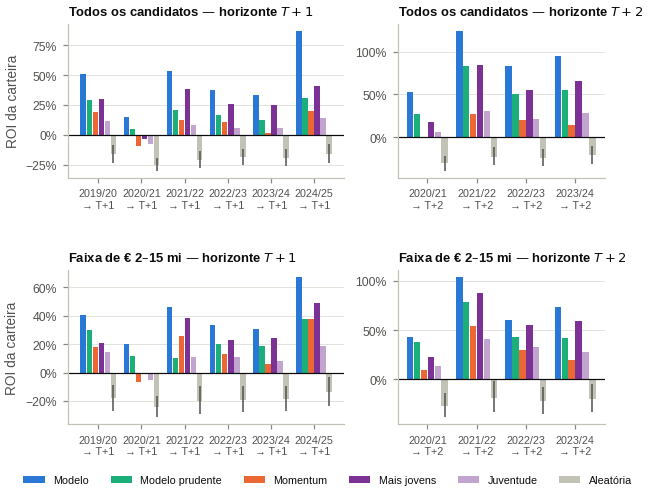

In [16]:
order = ["Modelo", "Modelo prudente", "Momentum", "Mais jovens", "Juventude", "Aleatória"]
colors = {"Modelo": pl.BLUE, "Modelo prudente": pl.AQUA, "Momentum": pl.ORANGE, "Mais jovens": "#7b3294",
          "Juventude": "#c2a5cf", "Aleatória": pl.NEUTRAL}
fig, axes = plt.subplots(2, 2, figsize=pl.figsize(12), gridspec_kw={"wspace": 0.22, "hspace": 0.6, "width_ratios": [4, 3]})
for (row, universe), (col, k) in [((r, u), (c, k)) for r, u in enumerate(UNIVERSES) for c, k in enumerate(HORIZONS)]:
    ax = axes[row, col]
    s = strat[is_main & (strat["horizonte"] == f"T+{k}") & (strat["universo"] == universe)]
    seasons = list(dict.fromkeys(s["temporada"]))
    width = 0.14
    for j, name in enumerate(order):
        v = s[s["estrategia"] == name].set_index("temporada").reindex(seasons)
        x = np.arange(len(seasons)) + (j - (len(order) - 1) / 2) * width
        ax.bar(x, v["roi_carteira_pct"], width=width * 0.92, color=colors[name], label=name)
        if name == "Aleatória":
            ax.vlines(x, v["roi_p05"], v["roi_p95"], color=pl.INK_SECONDARY, linewidth=1)
    ax.axhline(0, color=pl.INK, linewidth=0.8)
    ax.set_xticks(range(len(seasons)), [f"{t}\n→ T+{k}" for t in seasons], fontsize=7)
    ax.yaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_title(f"{universe} — horizonte $T+{k}$", fontsize=8.5)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("ROI da carteira")
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[n]) for n in order]
fig.legend(handles, order, loc="upper center", bbox_to_anchor=(0.5, 0.03), ncol=6, fontsize=7)
FIG.save(fig, "fig08_backtest_estrategias",
         "ROI realizado das carteiras de recrutamento por estratégia e temporada de decisão (backtest fora da amostra)",
         note="Cenário principal: compra por V_T × 1,10, venda por V_{T+k} × 0,90 e atletas sem V_{T+k} valendo zero. "
              "Carteiras com 10% dos candidatos; Mais jovens: os 10% de menor idade. Haste na estratégia aleatória: "
              "intervalo de 5% a 95% de 2.000 sorteios.")
plt.show()

In [17]:
# Teste do sinal entre temporadas, custo de equilíbrio e dependência dos maiores acertos (carteira do modelo)
sign_rows, be_rows = [], []
for (universe, horizon, cb, cv, miss), g in strat.groupby(["universo", "horizonte", "custo_compra", "custo_venda", "ausentes"]):
    w = g.pivot_table(index="temporada", columns="estrategia", values="roi_carteira_pct")
    wins = int((w["Modelo"] > w["Aleatória"]).sum())
    sign_rows.append({"universo": universe, "horizonte": horizon, "custo_compra": cb, "custo_venda": cv, "ausentes": miss,
                      "temporadas": len(w), "vitorias_vs_aleatoria": wins, "p_sinal": it.sign_test(wins, len(w)),
                      "vitorias_vs_momentum": int((w["Modelo"] > w["Momentum"]).sum()),
                      "vitorias_vs_mais_jovens": int((w["Modelo"] > w["Mais jovens"]).sum()),
                      "p_sinal_vs_mais_jovens": it.sign_test(int((w["Modelo"] > w["Mais jovens"]).sum()), len(w)),
                      "roi_medio_modelo": w["Modelo"].mean(), "roi_medio_mais_jovens": w["Mais jovens"].mean(),
                      "roi_medio_aleatoria": w["Aleatória"].mean()})
for (universe, flt), k in [(u, k) for u in UNIVERSES.items() for k in HORIZONS]:
    for season, cands in flt(sim[sim["horizon"] == k]).groupby("season"):
        sel = it.top_k(cands, "dv_pct_pred_mean", max(1, len(cands) // 10))
        for miss in MISSING:
            be_rows.append({"universo": universe, "horizonte": f"T+{k}", "temporada": sp.season_label(season), "ausentes": miss,
                            "agio_equilibrio_pct": it.break_even_buy_cost(sel, MAIN["sell_cost"], miss) * 100,
                            "roi_sem_maior_acerto_pct": it.roi_without_top(sel, 1, miss),
                            "roi_sem_3_maiores_pct": it.roi_without_top(sel, 3, miss)})
signs, breakeven = pd.DataFrame(sign_rows), pd.DataFrame(be_rows)
save_csv(signs, "tab07b_teste_sinal_temporadas", index=False)
save_csv(breakeven, "tab07c_custo_equilibrio_e_concentracao", index=False)
display(signs[(signs["ausentes"] == MAIN["missing"])].round(3),
        breakeven[breakeven["ausentes"] == MAIN["missing"]].groupby(["universo", "horizonte"])[
            ["agio_equilibrio_pct", "roi_sem_maior_acerto_pct", "roi_sem_3_maiores_pct"]].mean().round(1))

,universo,horizonte,custo_compra,custo_venda,ausentes,temporadas,vitorias_vs_aleatoria,p_sinal,vitorias_vs_momentum,vitorias_vs_mais_jovens,p_sinal_vs_mais_jovens,roi_medio_modelo,roi_medio_mais_jovens,roi_medio_aleatoria
2,Faixa de € 2–15 mi,T+1,0.000,0.000,zero,6,6,0.016,6,6,0.016,70.854,54.011,-0.843
5,Faixa de € 2–15 mi,T+1,0.100,0.100,zero,6,6,0.016,6,6,0.016,39.790,26.009,-18.926
8,Faixa de € 2–15 mi,T+1,0.250,0.100,zero,6,6,0.016,6,6,0.016,23.015,10.888,-28.712
11,Faixa de € 2–15 mi,T+2,0.000,0.000,zero,4,4,0.062,4,4,0.062,108.213,91.049,-4.713
14,Faixa de € 2–15 mi,T+2,0.100,0.100,zero,4,4,0.062,4,4,0.062,70.356,56.313,-21.882
17,Faixa de € 2–15 mi,T+2,0.250,0.100,zero,4,4,0.062,4,4,0.062,49.913,37.556,-31.326
20,Todos os candidatos,T+1,0.000,0.000,zero,6,6,0.016,6,6,0.016,78.728,53.933,-1.270
23,Todos os candidatos,T+1,0.100,0.100,zero,6,6,0.016,6,6,0.016,46.232,25.945,-19.206
26,Todos os candidatos,T+1,0.250,0.100,zero,6,6,0.016,6,6,0.016,28.684,10.832,-28.979
29,Todos os candidatos,T+2,0.000,0.000,zero,4,4,0.062,4,4,0.062,130.757,89.977,-7.608


agio_equilibrio_pct  roi_sem_maior_acerto_pct  roi_sem_3_maiores_pct
universo            horizonte                                                                      
Faixa de € 2–15 mi  T+1                     53.800                    65.200                 57.800
                    T+2                     87.400                    99.300                 85.200
Todos os candidatos T+1                     60.900                    74.200                 67.900
                    T+2                    107.700                   123.900                114.300

**Leitura.** No cenário principal (custos de 10% na compra e na venda; quem sai da base vale zero), a
estratégia do modelo supera todas as alternativas em todas as temporadas, nos dois universos e nos dois
horizontes.

| ROI médio das temporadas, cenário principal | Modelo | Modelo prudente | *Momentum* | Mais jovens | Juventude | Aleatória |
|---|---|---|---|---|---|---|
| $T+1$, todos os candidatos | **46%** | 19% | 9% | 26% | 6,5% | −19% |
| $T+1$, faixa de € 2–15 mi | **40%** | 21% | 16% | 26% | 10% | −19% |
| $T+2$, todos os candidatos | **89%** | 54% | 15% | 55% | 22% | −24% |
| $T+2$, faixa de € 2–15 mi | **70%** | 50% | 28% | 56% | 29% | −22% |

- **Teste do sinal (H4).** O modelo vence a carteira aleatória e o *momentum* em 6 de 6 temporadas de
  $T+1$ ($p$ = 0,016) e em 4 de 4 de $T+2$ ($p$ = 0,063), em todos os cenários de custo e de tratamento
  dos ausentes.
- **Mais jovens** (referência acrescentada depois da revelação do teste; seção 9.2). Comprar os 10% de
  menor idade é a heurística mais forte: ROI de 26% em $T+1$ e de 55–56% em $T+2$. O modelo a supera em
  todas as temporadas e nos dois universos: 6 de 6 ($p$ = 0,016) e 4 de 4 ($p$ = 0,063). Como essa
  referência não consta do protocolo, ela não entra no veredito da H4.
- **Custos.** Sem custos, o ROI médio do modelo é de 79% em $T+1$ e 131% em $T+2$; com ágio de 25% na
  compra, de 29% e 66%. O ágio de equilíbrio (ROI zero) vai de 27% (2020/21) a 106% (2024/25) em $T+1$.
- **Intenção de tratar.** Poucos atletas da carteira saem da base (0 a 1 por temporada em $T+1$, até 5 em
  $T+2$), e os três tratamentos dão ROI quase idêntico.
- **Concentração.** Sem os três maiores acertos de cada carteira, o ROI sem custos de $T+1$ cai de 7 a 16
  p.p. e continua acima de 34% em todas as temporadas.
- **Ganho líquido e perdas.** 57% dos atletas da carteira do modelo têm ganho líquido de custos em $T+1$ e
  60% em $T+2$, contra 21% ao acaso e 42–46% das heurísticas. Perdas graves (abaixo de −50%): 7% e 17%,
  contra 12% e 27% do *momentum*.
- **Modelo prudente** (seleção pelo P10): ROI menor, com perdas graves semelhantes. A proteção pelo P10
  não compensou.
- **ROI previsto da carteira** (sem custos, nas dobras com camada de magnitude): 72% previsto contra 87%
  realizado em $T+1$, e 140% contra 131% em $T+2$. O modelo é conservador em $T+1$ e calibrado em $T+2$.
- **Ressalva.** De 2019/20 a 2023/24, as previsões vêm de dobras usadas na otimização. Só 2024/25 é
  inteiramente limpa: ROI de 87%, contra −16% ao acaso e 20% do *momentum*.

### 9.1 Cenário de orçamento de um clube médio e risco financeiro

O cenário simula um clube com **€ 40 milhões** por janela, que contrata até **6 atletas** na faixa de
**€ 2–15 milhões**. É o mercado típico de um clube médio, que exclui as promessas da base (preço
residual) e os atletas caros. A estratégia do modelo compra em ordem decrescente de retorno
esperado, com **diversificação**: no máximo dois atletas por posição e três por faixa etária. Custos e
atletas sem $V_{T+k}$ seguem o cenário principal. A referência sorteia a ordem de compra ao acaso (2.000 vezes), respeitando as mesmas
restrições. O risco é medido pela distribuição do ROI de carteira:
- **probabilidade de perda**;
- ***Value-at-Risk* (VaR) a 5%**, o ROI no pior quinto percentil;
- ***Conditional VaR* (CVaR)**, a média dos 5% piores casos.

A incerteza da carteira do modelo é estimada por *bootstrap* dos atletas selecionados.

,horizonte,temporada,teste_final,atletas,sem_alvo,investimento_mi,roi_modelo_pct,ganho_modelo_mi,roi_previsto_pct,p_perda_modelo,VaR5_modelo,CVaR5_modelo,roi_aleatorio_medio_pct,p_perda_aleatorio,VaR5_aleatorio,CVaR5_aleatorio,percentil_modelo_vs_aleatorio
0,T+1,2019/20,False,6,0,33.550,129.360,43.400,13.090,0.000,64.830,47.180,-18.780,0.800,-51.300,-56.940,99.950
1,T+1,2020/21,False,6,0,19.250,5.190,1.000,76.910,0.430,-28.410,-34.920,-24.770,0.890,-51.330,-56.740,90.950
2,T+1,2021/22,False,6,0,18.150,16.530,3.000,62.740,0.320,-23.300,-28.440,-20.520,0.830,-51.760,-57.330,91.050
3,T+1,2022/23,False,6,0,18.150,172.730,31.350,91.320,0.040,3.640,-14.460,-18.440,0.800,-51.120,-56.620,100.000
4,T+1,2023/24,False,6,0,24.200,22.730,5.500,89.810,0.220,-26.650,-35.890,-19.520,0.810,-50.910,-55.910,92.800
5,T+1,2024/25,True,6,0,22.000,140.550,30.920,101.290,0.010,12.640,5.000,-12.560,0.730,-49.050,-53.400,99.900
6,T+2,2020/21,False,6,0,22.550,-9.800,-2.210,40.800,0.600,-53.070,-58.690,-26.710,0.810,-68.710,-73.450,74.750
7,T+2,2021/22,False,6,0,20.900,554.550,115.900,65.000,0.000,183.150,115.140,-17.840,0.750,-66.440,-71.280,100.000
8,T+2,2022/23,False,6,0,31.350,194.550,60.990,133.630,0.050,-19.440,-30.950,-21.650,0.780,-67.030,-71.800,99.550
9,T+2,2023/24,True,6,0,20.350,78.670,16.010,180.210,0.310,-41.190,-43.960,-18.300,0.760,-65.310,-70.000,95.350


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig09_orcamento_risco.png


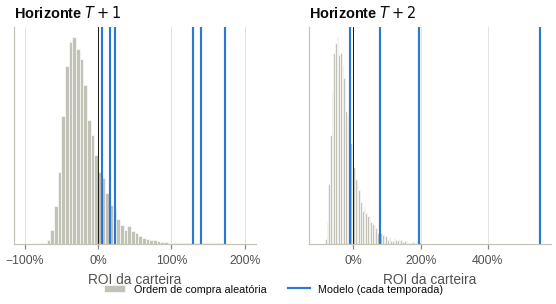

In [18]:
BUDGET, MAX_PRICE, MAX_PLAYERS = 40e6, PRICE_BAND[1], 6
DIVERSIFY = {"position_group": 2, band_col: 3}  # no máximo 2 por posição e 3 por faixa etária
risk_rows, dist_store = [], {}
for k in HORIZONS:
    for season, cands in UNIVERSES["Faixa de € 2–15 mi"](sim[sim["horizon"] == k]).groupby("season"):
        cands = cands.reset_index(drop=True)
        sel = it.budget_greedy(cands, "dv_pct_pred_mean", BUDGET, MAX_PRICE, MAX_PLAYERS, DIVERSIFY)
        m = it.portfolio_metrics(sel, **MAIN)
        boot = np.array([it.portfolio_metrics(sel.sample(len(sel), replace=True, random_state=int(s)), **MAIN)["roi_carteira_pct"]
                         for s in rng.integers(0, 1e9, 1000)])
        rand = []
        for _ in range(N_DRAWS):
            shuffled = cands.assign(_r=rng.random(len(cands)))
            rand.append(it.portfolio_metrics(it.budget_greedy(shuffled, "_r", BUDGET, MAX_PRICE, MAX_PLAYERS, DIVERSIFY),
                                             **MAIN)["roi_carteira_pct"])
        rand = np.array(rand)
        dist_store[(k, season)] = (m["roi_carteira_pct"], boot, rand)
        var_m, cvar_m = it.var_cvar(boot)
        var_r, cvar_r = it.var_cvar(rand)
        risk_rows.append({"horizonte": f"T+{k}", "temporada": sp.season_label(season), "teste_final": season == HOLDOUT[k],
                          "atletas": int(m["n"]), "sem_alvo": int(m["sem_alvo"]),
                          "investimento_mi": m["investimento_mi"], "roi_modelo_pct": m["roi_carteira_pct"],
                          "ganho_modelo_mi": m["ganho_liquido_mi"],
                          "roi_previsto_pct": (sel["value_T"] * sel["dv_pct_pred_mean"] / 100).sum() / sel["value_T"].sum() * 100,
                          "p_perda_modelo": float((boot < 0).mean()), "VaR5_modelo": var_m, "CVaR5_modelo": cvar_m,
                          "roi_aleatorio_medio_pct": rand.mean(), "p_perda_aleatorio": float((rand < 0).mean()),
                          "VaR5_aleatorio": var_r, "CVaR5_aleatorio": cvar_r,
                          "percentil_modelo_vs_aleatorio": float((rand < m["roi_carteira_pct"]).mean() * 100)})
risk = pd.DataFrame(risk_rows)
save_csv(risk, "tab08_orcamento_risco", index=False)
display(risk.round(2))

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(6.5), gridspec_kw={"wspace": 0.22})
for ax, k in zip(axes, HORIZONS):
    rand_all = np.concatenate([v[2] for (h, _), v in dist_store.items() if h == k])
    model_vals = [v[0] for (h, _), v in dist_store.items() if h == k]
    ax.hist(rand_all, bins=np.arange(-100, 205, 5), color=pl.NEUTRAL, edgecolor=pl.SURFACE, linewidth=0.4, density=True,
            label="Ordem de compra aleatória")
    for j, v in enumerate(model_vals):
        ax.axvline(v, color=pl.BLUE, linewidth=1.4, label="Modelo (cada temporada)" if j == 0 else None)
    ax.axvline(0, color=pl.INK, linewidth=0.6)
    ax.xaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_yticks([])
    ax.set_xlabel("ROI da carteira")
    ax.set_title(f"Horizonte $T+{k}$")
    ax.grid(axis="y", visible=False)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=7)
FIG.save(fig, "fig09_orcamento_risco",
         "Distribuição do ROI de carteiras com orçamento de € 40 milhões: modelo versus ordem de compra aleatória",
         note="Até 6 atletas com V_T entre € 2 e € 15 milhões, no máximo 2 por posição e 3 por faixa etária; compra por V_T × 1,10 "
              "e venda por V_{T+k} × 0,90, atletas sem V_{T+k} valendo zero. Histograma: 2.000 sorteios por temporada.")
plt.show()

**Leitura: risco de uma carteira concentrada.** No cenário de orçamento (até 6 atletas de € 2–15
mi, € 40 mi por janela, no máximo 2 por posição e 3 por faixa etária), o modelo investe € 18–34 mi por
temporada.

| Temporada de decisão ($T+1$) | ROI do modelo | Percentil frente a 2.000 carteiras aleatórias | P(perda) do modelo |
|---|---|---|---|
| 2019/20 | +129% | 99,9 | 0% |
| 2020/21 | +5% | 91 | 43% |
| 2021/22 | +17% | 91 | 32% |
| 2022/23 | +173% | 100 | 4% |
| 2023/24 | +23% | 93 | 22% |
| **2024/25 (teste)** | **+141%** | **99,9** | **1%** |

As carteiras aleatórias têm ROI médio de −25% a −13%, probabilidade de perda de 73–89%, VaR a 5% de −52%
a −49% e CVaR de −57% a −53%. Em $T+2$, o modelo fica entre os percentis 75 e 100: −10% em 2020/21,
+555% em 2021/22, +195% em 2022/23 e +79% no teste de 2023/24.

*Implicação gerencial.* O modelo desloca toda a distribuição de retorno para a direita, mas não elimina o
risco de cauda: com seis atletas, a probabilidade de perda da carteira do modelo chega a 22–43% nos anos
fracos de $T+1$ e a 60% em $T+2$ (2020/21, logo após a revisão de valores da pandemia). A decisão deve
combinar a previsão com o intervalo de 80% e com diversificação por posição e faixa etária.

### 9.2 O modelo como regra de compra (análise secundária)

O objetivo gerencial não é acertar quanto cada atleta vai valorizar, e sim decidir **quem comprar**: quem
vai se valorizar o bastante para pagar a operação. Esta seção avalia o modelo como regra de decisão,
com as mesmas previsões fora da amostra, sem nenhum ajuste novo.

**Valorização significativa** é a que supera o ponto de equilíbrio dos custos de transação. Comprar por
$V_T(1+c_b)$ e vender por $V_{T+k}(1-c_v)$ só dá lucro se

$$\Delta V\% > \frac{1+c_b}{1-c_v} - 1.$$

No cenário principal ($c_b = c_v = 10\%$), o limiar é de **22,2%**. Ele decorre dos custos fixados no
protocolo, e não dos resultados. A análise usa três rótulos:
- **Valorizou:** $\Delta V > 0$;
- **Paga 10% + 10%:** $\Delta V\% > 22{,}2\%$ (rótulo principal);
- **Paga 25% + 10%:** $\Delta V\% > 38{,}9\%$.

Quem sai da base conta como prejuízo total, como no cenário principal do *backtest*.

| Medida | Pergunta que responde |
|---|---|
| **AUC** | Probabilidade de um atleta que pagou a operação estar à frente de um que não pagou no *ranking* |
| **AP** (precisão média) | Precisão ao longo do *ranking*; a referência é a taxa-base |
| **Acerto do decil superior** | Dos 10% que o modelo mandaria comprar, quantos pagaram a operação |
| **Acerto do decil inferior** | Dos 10% que o modelo mandaria evitar, quantos teriam pago |
| **Probabilidade calibrada** | Qual a chance de *este* atleta pagar a operação |

Além do *momentum*, a referência principal é a heurística **"Mais jovens"**: os 10% de menor idade. Ela
é mais forte que a carteira de juventude sorteada, porque a idade é a variável mais importante do
modelo.

*Status:* análise definida depois da revelação do teste de 2024/25 e, portanto, **não pré-registrada**.
Ela não altera nenhum modelo, previsão ou critério de hipótese; o veredito da H4 continua o do
protocolo.

In [19]:
# Rótulos de decisão: a valorização realizada paga a operação? Quem sai da base conta como prejuízo total.
DECISION = {"valorizou": ("Valorizou (ΔV > 0)", 0.0, 0.0),
            "lucro_10_10": ("Paga custos de 10% + 10%", 0.10, 0.10),
            "lucro_25_10": ("Paga custos de 25% + 10%", 0.25, 0.10)}
MAIN_LABEL = "lucro_10_10"
dec = sim.assign(idade_invertida=-sim["age"], avaliacao=np.where(sim["is_holdout"], "teste final", "desenvolvimento"))
for key, (name, cb, cv) in DECISION.items():
    dec[key] = it.pays_costs(dec["dv_pct_true"], cb, cv)
    print(f"{name}: ΔV% > {it.break_even_return(cb, cv):.1%} | taxa-base {dec[key].mean():.1%}")
DEC_SCORES = {"Modelo": "dv_pct_pred_mean", "Modelo prudente": "q10_conf", "Momentum": "log_return_lag1",
              "Mais jovens": "idade_invertida"}
rows = []
for (k, season), g in dec.groupby(["horizon", "season"]):
    for key in DECISION:
        for name, col in DEC_SCORES.items():
            rows.append({"horizonte": f"T+{k}", "temporada": sp.season_label(season), "avaliacao": g["avaliacao"].iloc[0],
                         "rotulo": key, "estrategia": name, **it.decision_metrics(g[key], g[col])})
disc = pd.DataFrame(rows)
save_csv(disc, "tab13_decisao_por_temporada", index=False)
disc_sum = disc.groupby(["horizonte", "avaliacao", "rotulo", "estrategia"], sort=False)[
    ["taxa_base", "auc", "ap", "acerto_topo", "acerto_base"]].mean()
save_csv(disc_sum, "tab13b_decisao_resumo")
display(disc_sum.xs(MAIN_LABEL, level="rotulo").unstack("estrategia")[["auc", "acerto_topo"]].round(3))

Valorizou (ΔV > 0): ΔV% > 0.0% | taxa-base 26.1%
Paga custos de 10% + 10%: ΔV% > 22.2% | taxa-base 20.8%
Paga custos de 25% + 10%: ΔV% > 38.9% | taxa-base 16.9%


auc                                      acerto_topo                                     
estrategia                Modelo Modelo prudente Momentum Mais jovens      Modelo Modelo prudente Momentum Mais jovens
horizonte avaliacao                                                                                                   
T+1       desenvolvimento  0.793           0.756    0.675       0.763       0.553           0.487    0.428       0.496
          teste final      0.821           0.780    0.682       0.802       0.670           0.558    0.497       0.558
T+2       desenvolvimento  0.824           0.799    0.671       0.805       0.589           0.562    0.420       0.550
          teste final      0.833           0.798    0.682       0.835       0.615           0.559    0.420       0.631

In [20]:
# IC 95% por bootstrap de clubes × temporada no teste final: AUC do modelo e vantagem sobre as heurísticas
def auc_gap(f: pd.DataFrame, key: str, ref: str | None = None) -> float:
    if ref is None:
        return it.auc(f[key], f["dv_pct_pred_mean"])
    m = f[ref].notna()                       # a comparação usa só os atletas com as duas pontuações
    return it.auc(f.loc[m, key], f.loc[m, "dv_pct_pred_mean"]) - it.auc(f.loc[m, key], f.loc[m, ref])


ci_rows = []
for k in HORIZONS:
    g = dec[(dec["horizon"] == k) & dec["is_holdout"]].reset_index(drop=True)
    clusters = md.cluster_codes(g)
    for key in ("valorizou", MAIN_LABEL):
        for name, ref in (("AUC do modelo", None), ("Modelo − mais jovens", "idade_invertida"),
                          ("Modelo − momentum", "log_return_lag1")):
            ci = md.cluster_bootstrap(g, lambda f: auc_gap(f, key, ref), clusters, n_boot=1000)
            ci_rows.append({"horizonte": f"T+{k}", "rotulo": key, "estatistica": name, **ci})
auc_ci = pd.DataFrame(ci_rows)
save_csv(auc_ci, "tab13c_decisao_auc_teste_ic95", index=False)
display(auc_ci.round(3))

,horizonte,rotulo,estatistica,estimate,ci_low,ci_high,se,n_clusters
0,T+1,valorizou,AUC do modelo,0.810,0.789,0.830,0.010,96
1,T+1,valorizou,Modelo − mais jovens,0.015,0.005,0.025,0.005,96
2,T+1,valorizou,Modelo − momentum,0.119,0.095,0.143,0.012,96
3,T+1,lucro_10_10,AUC do modelo,0.821,0.800,0.842,0.011,96
4,T+1,lucro_10_10,Modelo − mais jovens,0.020,0.009,0.031,0.006,96
5,T+1,lucro_10_10,Modelo − momentum,0.132,0.105,0.159,0.014,96
6,T+2,valorizou,AUC do modelo,0.825,0.801,0.848,0.012,96
7,T+2,valorizou,Modelo − mais jovens,-0.000,-0.012,0.010,0.006,96
8,T+2,valorizou,Modelo − momentum,0.143,0.112,0.171,0.015,96
9,T+2,lucro_10_10,AUC do modelo,0.833,0.810,0.855,0.011,96


In [21]:
# A regra frente à idade: dentro de cada faixa etária, o modelo ainda separa quem paga a operação?
rows = []
for (k, season, band), g in dec.groupby(["horizon", "season", band_col], observed=True):
    for name in ("Modelo", "Mais jovens", "Momentum"):
        rows.append({"horizonte": f"T+{k}", "avaliacao": g["avaliacao"].iloc[0], "faixa": band, "estrategia": name,
                     **it.decision_metrics(g[MAIN_LABEL], g[DEC_SCORES[name]])})
by_band = (pd.DataFrame(rows).groupby(["horizonte", "avaliacao", "faixa", "estrategia"], sort=False)
           .agg(n=("n", "sum"), taxa_base=("taxa_base", "mean"), auc=("auc", "mean"), acerto_topo=("acerto_topo", "mean"))
           .sort_index(level=["horizonte", "avaliacao", "faixa"], sort_remaining=False))
save_csv(by_band, "tab14_decisao_por_faixa_etaria")
display(by_band.unstack("estrategia")[["taxa_base", "auc", "acerto_topo"]].round(3))

taxa_base                         auc                 acerto_topo                
estrategia                      Mais jovens Modelo Momentum Mais jovens Modelo Momentum Mais jovens Modelo Momentum
horizonte avaliacao       faixa                                                                                    
T+1       desenvolvimento 16–23       0.409  0.409    0.389       0.577  0.669    0.581       0.547  0.695    0.470
                          24–28       0.216  0.216    0.216       0.575  0.660    0.573       0.254  0.422    0.329
                          29–32       0.041  0.041    0.041       0.628  0.714    0.571       0.055  0.148    0.081
                          33+         0.022  0.022    0.023       0.576  0.709    0.607       0.021  0.081    0.068
          teste final     16–23       0.462  0.462    0.440       0.607  0.694    0.582       0.709  0.673    0.490
                          24–28       0.201  0.201    0.200       0.593  0.646    0.528       0.188  0.388    0.288
                          29–32       0.023  0.023    0.023       0.774  0.674    0.462       0.045  0.045    0.000
                          33+         0.000  0.000    0.000         NaN    NaN      NaN       0.000  0.000    0.000
T+2       desenvolvimento 16–23       0.456  0.456    0.430       0.586  0.653    0.552       0.613  0.707    0.493
                          24–28       0.192  0.192    0.193       0.607  0.676    0.541       0.260  0.372    0.294
                          29–32       0.028  0.028    0.028       0.616  0.700    0.556       0.069  0.090    0.055
                          33+         0.005  0.005    0.005       0.703  0.797    0.291       0.018  0.000    0.000
          teste final     16–23       0.483  0.483    0.470       0.626  0.628    0.554       0.685  0.722    0.646
                          24–28       0.187  0.187    0.187       0.697  0.678    0.538       0.367  0.367    0.192
                          29–32       0.014  0.014    0.014       0.740  0.720    0.603       0.068  0.045    0.047
                          33+         0.006  0.006    0.006       0.222  0.966    0.896       0.000  0.059    0.059

In [22]:
# Probabilidade de pagar a operação do cenário principal, calibrada só com as temporadas anteriores
dec = dec.join(pd.concat([it.exceedance_probability(g, "dv_pct_pred_mean", MAIN_LABEL) for _, g in dec.groupby("horizon")]))
cal = dec[dec["prob"].notna()]
prob_rows, rule_rows = [], []
for (k, season), g in cal.groupby(["horizon", "season"]):
    common = {"horizonte": f"T+{k}", "temporada": sp.season_label(season), "avaliacao": g["avaliacao"].iloc[0]}
    y = g[MAIN_LABEL]
    brier, brier_ref = np.mean((g["prob"] - y) ** 2), np.mean((g["clim"] - y) ** 2)
    prob_rows.append({**common, "n": len(g), "prob_media": g["prob"].mean(), "freq_observada": y.mean(),
                      "brier": brier, "brier_referencia": brier_ref, "brier_skill": 1 - brier / brier_ref})
    rules = [("decil superior", g.nlargest(max(1, len(g) // 10), "dv_pct_pred_mean"))]
    rules += [(f"P ≥ {thr:.0%}", g[g["prob"] >= thr]) for thr in (0.5, 0.6)]
    for rule, sel in rules:
        rule_rows.append({**common, "regra": rule, "selecionados": len(sel), "pct_candidatos": len(sel) / len(g) * 100,
                          "acerto": sel[MAIN_LABEL].mean() if len(sel) else np.nan,
                          "roi_cenario_principal_pct": it.portfolio_metrics(sel, **MAIN)["roi_carteira_pct"] if len(sel) else np.nan})
reliab = pd.concat([it.reliability_table(g["prob"], g[MAIN_LABEL]).assign(horizonte=f"T+{k}", avaliacao=ev)
                    for (k, ev), g in cal.groupby(["horizon", "avaliacao"])])
reliab = reliab[["horizonte", "avaliacao", "faixa", "n", "prob_prevista", "freq_observada"]]
prob_tab, rule_tab = pd.DataFrame(prob_rows), pd.DataFrame(rule_rows)
save_csv(prob_tab, "tab15_decisao_probabilidade_calibrada", index=False)
save_csv(reliab, "tab15b_decisao_confiabilidade", index=False)
save_csv(rule_tab, "tab15c_decisao_regra_por_limiar", index=False)
display(prob_tab.round(3), reliab.round(3), rule_tab.round(3))

,horizonte,temporada,avaliacao,n,prob_media,freq_observada,brier,brier_referencia,brier_skill
0,T+1,2021/22,desenvolvimento,2010,0.299,0.181,0.141,0.148,0.050
1,T+1,2022/23,desenvolvimento,1987,0.218,0.196,0.128,0.158,0.192
2,T+1,2023/24,desenvolvimento,1952,0.227,0.204,0.133,0.163,0.180
3,T+1,2024/25,teste final,1970,0.228,0.217,0.131,0.170,0.229
4,T+2,2022/23,desenvolvimento,1987,0.326,0.209,0.140,0.165,0.154
5,T+2,2023/24,teste final,1952,0.268,0.214,0.132,0.168,0.212


,horizonte,avaliacao,faixa,n,prob_prevista,freq_observada
0,T+1,desenvolvimento,"(-0.001, 0.1]",1521,0.057,0.022
1,T+1,desenvolvimento,"(0.1, 0.2]",1436,0.150,0.104
2,T+1,desenvolvimento,"(0.2, 0.3]",909,0.263,0.211
3,T+1,desenvolvimento,"(0.3, 0.4]",715,0.342,0.281
4,T+1,desenvolvimento,"(0.4, 0.5]",889,0.448,0.336
5,T+1,desenvolvimento,"(0.5, 0.6]",372,0.568,0.530
6,T+1,desenvolvimento,"(0.6, 1.0]",107,0.759,0.738
0,T+1,teste final,"(-0.001, 0.1]",670,0.045,0.022
1,T+1,teste final,"(0.1, 0.2]",373,0.145,0.155
2,T+1,teste final,"(0.2, 0.3]",382,0.262,0.230


,horizonte,temporada,avaliacao,regra,selecionados,pct_candidatos,acerto,roi_cenario_principal_pct
0,T+1,2021/22,desenvolvimento,decil superior,201,10.000,0.522,53.348
1,T+1,2021/22,desenvolvimento,P ≥ 50%,94,4.677,0.617,169.894
2,T+1,2021/22,desenvolvimento,P ≥ 60%,3,0.149,0.667,168.577
3,T+1,2022/23,desenvolvimento,decil superior,198,9.965,0.591,37.436
4,T+1,2022/23,desenvolvimento,P ≥ 50%,160,8.052,0.619,44.251
5,T+1,2022/23,desenvolvimento,P ≥ 60%,45,2.265,0.800,289.281
6,T+1,2023/24,desenvolvimento,decil superior,195,9.990,0.528,33.316
7,T+1,2023/24,desenvolvimento,P ≥ 50%,225,11.527,0.529,33.530
8,T+1,2023/24,desenvolvimento,P ≥ 60%,59,3.023,0.695,108.106
9,T+1,2024/25,teste final,decil superior,197,10.000,0.670,87.218


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig12_regra_de_compra.png


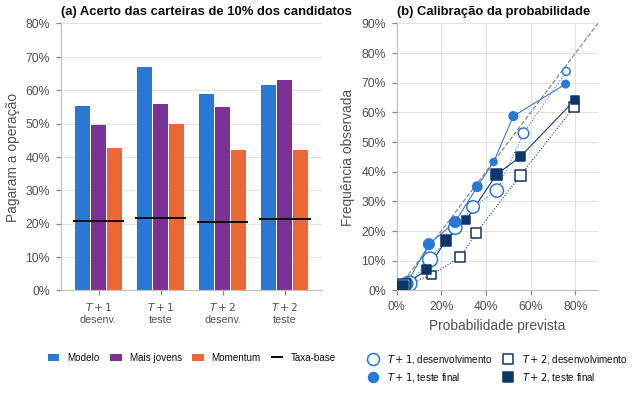

In [23]:
STRAT_COLORS = {"Modelo": pl.BLUE, "Mais jovens": "#7b3294", "Momentum": pl.ORANGE}
HORIZON_COLORS = {"T+1": pl.BLUE, "T+2": "#0d366b"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=pl.figsize(8), gridspec_kw={"wspace": 0.32, "width_ratios": [1.3, 1]})
groups = [(f"T+{k}", ev) for k in HORIZONS for ev in ("desenvolvimento", "teste final")]
top = disc_sum.xs(MAIN_LABEL, level="rotulo")
x, width = np.arange(len(groups)), 0.26
for j, (name, color) in enumerate(STRAT_COLORS.items()):
    ax1.bar(x + (j - 1) * width, [top.loc[(h, ev, name), "acerto_topo"] for h, ev in groups], width=width * 0.92,
            color=color, label=name)
ax1.hlines([top.loc[(h, ev, "Modelo"), "taxa_base"] for h, ev in groups], x - 1.6 * width, x + 1.6 * width,
           color=pl.INK, linewidth=1.3, label="Taxa-base")
ax1.set_xticks(x, [f"${h}$\n" + ("teste" if ev == "teste final" else "desenv.") for h, ev in groups], fontsize=7)
ax1.yaxis.set_major_formatter(pl.pct_formatter(0, 1))
ax1.set_ylim(0, 0.8)
ax1.set_ylabel("Pagaram a operação")
ax1.set_title("(a) Acerto das carteiras de 10% dos candidatos", fontsize=8.5)
ax1.grid(axis="x", visible=False)
handles, names = ax1.get_legend_handles_labels()
ax1.legend(handles[1:] + handles[:1], names[1:] + names[:1], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4,
           fontsize=6.5, handlelength=1.2, columnspacing=1)
for (h, ev), g in reliab.groupby(["horizonte", "avaliacao"], sort=False):
    test = ev == "teste final"
    ax2.plot(g["prob_prevista"], g["freq_observada"], color=HORIZON_COLORS[h], linewidth=0.7,
             linestyle="-" if test else ":", zorder=2)
    ax2.scatter(g["prob_prevista"], g["freq_observada"], s=np.sqrt(g["n"]) * 2.5, marker="o" if h == "T+1" else "s",
                facecolor=HORIZON_COLORS[h] if test else pl.SURFACE, edgecolor=HORIZON_COLORS[h], linewidth=1,
                label=f"${h}$, {ev}", zorder=3)
ax2.plot([0, 1], [0, 1], color=pl.INK_MUTED, linewidth=0.8, linestyle="--", zorder=1)
ax2.set_xlim(0, 0.9)
ax2.set_ylim(0, 0.9)
ax2.xaxis.set_major_formatter(pl.pct_formatter(0, 1))
ax2.yaxis.set_major_formatter(pl.pct_formatter(0, 1))
ax2.set_xlabel("Probabilidade prevista")
ax2.set_ylabel("Frequência observada")
ax2.set_title("(b) Calibração da probabilidade", fontsize=8.5)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=6.5, handlelength=1.2, columnspacing=1)
FIG.save(fig, "fig12_regra_de_compra",
         "Desempenho do modelo como regra de compra: acerto das carteiras e calibração da probabilidade de a "
         "valorização pagar os custos da operação",
         note="Pagar a operação: valorização realizada acima do ponto de equilíbrio de custos de 10% na compra e 10% na "
              "venda (ΔV% > 22,2%); atletas sem V_{T+k} contam como prejuízo. (a) Carteiras com os 10% de maior retorno "
              "esperado (Modelo), de menor idade (Mais jovens) ou de maior valorização passada (Momentum); média das "
              "temporadas de desenvolvimento (desenv.) e teste final (2024/25 em T+1; 2023/24 em T+2). (b) Probabilidade calibrada por regressão isotônica só com as temporadas anteriores, a partir "
              "da 3ª dobra; área dos marcadores proporcional ao número de atletas.")
plt.show()

**Leitura (regra de compra).** Cerca de 21% dos atletas se valorizam o bastante para pagar a operação
do cenário principal ($\Delta V\%$ > 22,2%).

| Pagar custos de 10% + 10% | $T+1$ desenv. | $T+1$ teste | $T+2$ desenv. | $T+2$ teste |
|---|---|---|---|---|
| AUC do modelo | 0,79 | **0,82** [0,80; 0,84] | 0,82 | **0,83** [0,81; 0,86] |
| AUC dos 10% mais jovens | 0,76 | 0,80 | 0,81 | 0,84 |
| Decil superior do modelo: % que pagou | 55% | **67%** | 59% | **62%** |
| 10% mais jovens: % que pagou | 50% | 56% | 55% | 63% |
| Decil inferior do modelo: % que pagou | 1% | 0% | 1% | 0% |

- **Discriminação.** O decil superior paga a operação cerca de três vezes a taxa-base; o inferior,
  praticamente nunca. Os outros limiares dão o mesmo quadro (AUC de 0,81–0,83 para "valorizou" e de 0,83
  para custos de 25% + 10%).
- **Idade.** Os 10% mais jovens já separam bem quem paga a operação. No teste, o modelo supera essa
  heurística em $T+1$ (+0,020 de AUC [0,009; 0,031]) e empata em $T+2$ (−0,002 [−0,013; 0,009]).
- **Dentro das faixas** (`tab14`). A vantagem do modelo é mais clara no auge: entre os atletas de 24–28
  anos, 42% e 39% do decil superior pagaram a operação em $T+1$ (desenvolvimento e teste), contra 25% e
  19% dos mais jovens da faixa. Entre os jovens de 16–23, ela some no teste de $T+1$ (67% contra 71%).
- **Probabilidade.** Calibrada só com o passado, é confiável em $T+1$: no teste, quem recebeu mais de
  60% pagou em 70% dos casos. O escore de Brier fica 18–23% abaixo do da taxa-base com pelo menos duas
  temporadas de histórico. Em $T+2$, a probabilidade é otimista: 79–80% previstos contra 62–64%
  observados no topo.
- **Regra "P ≥ 60%".** Em $T+1$, seleciona de 3 a 92 atletas por temporada (até 5% dos candidatos), com
  acerto de 67–80%, contra 52–67% do decil superior. A carteira fica pequena e concentrada em promessas
  de clubes de elite.

*Implicação.* Para a pergunta "este atleta vai se valorizar o bastante para pagar a operação?", o modelo
responde bem, mas boa parte da resposta vem da idade. A contribuição própria do modelo está em ordenar o
auge, descartar quem não tem chance e escolher, entre os jovens, os de maior valorização. Isso aparece
no retorno: 46% contra 26% dos mais jovens em $T+1$ e 89% contra 55% em $T+2$. A regressão do log-retorno
continua sendo o motor da decisão.

## 10. Mapa de oportunidades e lista de observação (teste final)

O mapa de oportunidades é o artefato gerencial do estudo: cada atleta posicionado pelo **retorno
esperado** (eixo x) e pelo **cenário pessimista** (P10, eixo y). A lista mostra as 15 maiores
oportunidades na faixa de € 2–15 milhões no teste final de $T+1$ e o que aconteceu um ano depois.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/05_model_interpretation/fig10_mapa_oportunidades.png


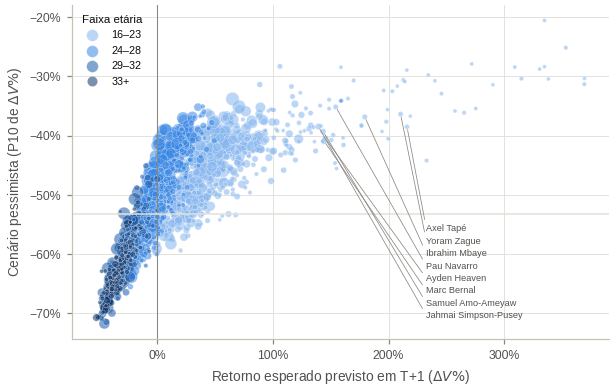

Lista de observação: 80% se valorizaram; ROI 258.8% (sem custos), 193.6% (cenário principal); 73% dentro do intervalo de 80%


,fb_player,fb_team,league,faixa,position_group,valor_T_mi,previsto_mediana,previsto_esperanca,cenario_p10,cenario_p90,realizado,valor_T1_mi,sem_valor_em_T1
11723,Axel Tapé,Paris SG,FRA-Ligue 1,16–23,DEF,2.000,140.800,216.000,-38.500,"1,210.100",300.000,8.000,False
11714,Yoram Zague,Paris SG,FRA-Ligue 1,16–23,DEF,2.500,136.600,210.400,-36.400,"1,015.800",-28.000,1.800,False
11564,Ibrahim Mbaye,Paris SG,FRA-Ligue 1,16–23,ATA,3.000,113.000,179.500,-36.800,721.400,900.000,30.000,False
11091,Pau Navarro,Villarreal,ESP-La Liga,16–23,DEF,3.000,93.900,154.400,-35.200,371.800,400.000,15.000,False
11739,Ayden Heaven,Manchester Utd,ENG-Premier League,16–23,DEF,5.000,87.200,145.600,-40.500,530.900,500.000,30.000,False
11663,Marc Bernal,Barcelona,ESP-La Liga,16–23,MEI,5.000,86.200,144.300,-40.900,403.400,500.000,30.000,False
11579,Samuel Amo-Ameyaw,Strasbourg,FRA-Ligue 1,16–23,ATA,4.000,85.600,143.500,-39.300,390.800,100.000,8.000,False
11831,Jahmai Simpson-Pusey,Manchester City,ENG-Premier League,16–23,DEF,5.000,82.400,139.400,-38.500,473.500,80.000,9.000,False
11750,Tyler Fredricson,Manchester Utd,ENG-Premier League,16–23,DEF,3.000,80.600,137.000,-42.600,396.500,0.000,3.000,False
11169,Louis Leroux,Nantes,FRA-Ligue 1,16–23,MEI,4.000,77.500,132.900,-38.200,335.600,150.000,10.000,False


In [24]:
k = 1
h = sim[(sim["horizon"] == k) & sim["is_holdout"]].copy()
h["p10_pct"] = np.expm1(h["q10_conf"]) * 100
h["p90_pct"] = np.expm1(h["q90_conf"]) * 100
fig, ax = plt.subplots(figsize=pl.figsize(10))
for band, color in zip(BANDS, pl.AGE_BAND_COLORS):
    m = h[band_col] == band
    ax.scatter(h.loc[m, "dv_pct_pred_mean"], h.loc[m, "p10_pct"], s=6 + h.loc[m, "value_T"] / 1e6 * 2.2, color=color, alpha=0.55,
               linewidths=0.3, edgecolors=pl.SURFACE, label=band)
watch = h[h["value_T"].between(*PRICE_BAND)].nlargest(15, "dv_pct_pred_mean")
# rótulos numa coluna no canto inferior direito, vazio: o ponto mais à direita liga-se ao rótulo de cima,
# o que evita linhas cruzadas
(x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
lab = watch.head(8).sort_values("dv_pct_pred_mean", ascending=False)
for y_lab, (_, r) in zip(np.linspace(y0 + 0.33 * (y1 - y0), y0 + 0.07 * (y1 - y0), len(lab)), lab.iterrows()):
    ax.annotate(r["fb_player"], (r["dv_pct_pred_mean"], r["p10_pct"]), xytext=(x0 + 0.66 * (x1 - x0), y_lab),
                textcoords="data", fontsize=6, color=pl.INK_SECONDARY, va="center", ha="left",
                arrowprops={"arrowstyle": "-", "color": pl.INK_MUTED, "linewidth": 0.5, "shrinkA": 1, "shrinkB": 2,
                            "relpos": (0, 0.5)})   # a linha parte da borda esquerda do rótulo, sem cortar o texto
ax.axvline(0, color=pl.INK_MUTED, linewidth=0.7)
ax.axhline(h["p10_pct"].median(), color=pl.GRID, linewidth=1)
ax.xaxis.set_major_formatter(pl.pct_formatter(0))
ax.yaxis.set_major_formatter(pl.pct_formatter(0))
ax.set_xlabel("Retorno esperado previsto em T+1 ($\\Delta V\\%$)")
ax.set_ylabel("Cenário pessimista (P10 de $\\Delta V\\%$)")
ax.legend(title="Faixa etária", fontsize=7, title_fontsize=7.5, loc="upper left", markerscale=1.2)
FIG.save(fig, "fig10_mapa_oportunidades",
         f"Mapa de oportunidades de recrutamento em 30/06/20{HOLDOUT[1][2:]}: retorno esperado versus cenário pessimista em T+1",
         note="Tamanho do ponto proporcional a V_T. Rótulos: oito maiores retornos esperados na faixa de € 2–15 milhões. Previsões fora da amostra.")
plt.show()

watch_tab = watch.assign(
    valor_T_mi=watch["value_T"] / 1e6, previsto_mediana=watch["dv_pct_pred_median"], previsto_esperanca=watch["dv_pct_pred_mean"],
    cenario_p10=watch["p10_pct"], cenario_p90=watch["p90_pct"], realizado=watch["dv_pct_true"],
    valor_T1_mi=(watch["value_T"] + watch["dv_true"]) / 1e6,
)[["fb_player", "fb_team", "league", band_col, "position_group", "valor_T_mi", "previsto_mediana", "previsto_esperanca",
   "cenario_p10", "cenario_p90", "realizado", "valor_T1_mi"]].rename(columns={band_col: "faixa"})
watch_tab["sem_valor_em_T1"] = ~watch["has_target"].to_numpy()
save_csv(watch_tab, "tab09_lista_observacao_teste_final", index=False)
inside = ((watch_tab["realizado"] >= watch_tab["cenario_p10"]) & (watch_tab["realizado"] <= watch_tab["cenario_p90"])).mean()
print(f"Lista de observação: {(watch_tab['realizado'] > 0).mean() * 100:.0f}% se valorizaram; "
      f"ROI {it.portfolio_metrics(watch)['roi_carteira_pct']:.1f}% (sem custos), {it.portfolio_metrics(watch, **MAIN)['roi_carteira_pct']:.1f}% "
      f"(cenário principal); {inside * 100:.0f}% dentro do intervalo de 80%")
watch_tab.round(1)

**Leitura.** Na lista de observação, com as 15 maiores oportunidades de € 2–15 mi apontadas em
30/06/2025 (teste pré-registrado), **80% se valorizaram** até 30/06/2026. O ROI da lista foi de **259%**
sem custos e de **194%** no cenário principal, e 73% dos realizados caíram dentro do intervalo de 80%.
Os destaques são **Ibrahim Mbaye** (PSG, € 3 mi → € 30 mi), **Jaydee Canvot** (Toulouse, € 4 mi → € 28
mi), **Ayden Heaven** (Manchester United, € 5 mi → € 30 mi), **Marc Bernal** (Barcelona, € 5 mi → € 30
mi) e **Pau Navarro** (Villarreal, € 3 mi → € 15 mi). A maior perda foi a de Yoram Zague (PSG, −28%).

**Leitura crítica.** Os 15 atletas têm de 16 a 23 anos, e 10 deles jogam em clubes de elite (PSG,
Manchester United, Manchester City, Barcelona, Juventus e Aston Villa). O modelo aprendeu que um jovem
barato num elenco caro (baixa participação no valor do elenco) tende a ser reavaliado para cima quando
ganha minutos. Isso identifica **onde** a valorização acontece, mas não garante que ela possa ser
**comprada**: o $V_T$ de uma promessa de um clube de elite não é o preço pelo qual ela seria vendida.
Para um clube médio, a carteira diversificada do cenário de orçamento (seção 9.1) é a referência mais
realista.

O mapa de oportunidades (`fig10_mapa_oportunidades`) traduz a decisão em dois eixos. Os jovens ocupam a região de maior
retorno esperado, com cenário pessimista (P10) em torno de −30% a −45%. Os veteranos concentram-se no
quadrante de retorno negativo e P10 abaixo de −60%.

## 11. Lista prospectiva: 2024/25 → 30/06/2027

O modelo final de $T+2$, treinado com todos os alvos já observados, é aplicado aos atletas de 2024/25,
com informação até 30/06/2025, para prever o valor em 30/06/2027, que ainda não existe. A lista das 15
maiores oportunidades de € 2–15 milhões é gravada com a data e o *commit* do código: uma **previsão
verificável**, que poderá ser conferida quando o Transfermarkt publicar os valores de junho de 2027.

*Ressalva.* A lista é emitida em outubro de 2026, quando o valor intermediário de 30/06/2026 já é
público; o modelo não o usa. Ela serve à verificação científica do horizonte de duas temporadas, e não
como recomendação de compra na data de emissão.

In [25]:
import joblib

k, season = 2, cfg.feature_seasons[-1]
entry = manifest["horizons"]["T2"]
d = panel[panel["season"] == season].copy()
y, _ = predict_final(2, d)
lay = entry["magnitude_layer"]
d["y_pred_cal"] = lay["a"] + lay["b"] * y
d["dv_pct_pred_median"] = np.expm1(d["y_pred_cal"]) * 100
d["dv_pct_pred_mean"] = (np.exp(d["y_pred_cal"]) * d["age_band"].map(lay["smearing_by_age_band"]).fillna(1.0) - 1) * 100
for q in ("q10", "q90"):
    d[q] = joblib.load(paths.root / entry[q]["path"])["model"].predict(d)
adj = lay["conformal_adj"]
d["p10_pct"] = np.expm1(np.minimum(d["q10"], d["y_pred_cal"]) - adj) * 100
d["p90_pct"] = np.expm1(np.maximum(d["q90"], d["y_pred_cal"]) + adj) * 100
# versão dos modelos: o commit do protocolo pré-registrado (estável em reexecuções posteriores)
commit = subprocess.run(["git", "log", "-1", "--format=%h", "--", "reports/protocol_v3.json"], cwd=paths.root,
                        capture_output=True, text=True).stdout.strip()
issued = pd.Timestamp.now().date().isoformat()
prospect = (d[d["value_T"].between(*PRICE_BAND)].nlargest(15, "dv_pct_pred_mean")
            [["fb_player", "fb_team", "league", "age_band", "position_group", "value_T", "dv_pct_pred_median", "dv_pct_pred_mean",
              "p10_pct", "p90_pct"]]
            .assign(valor_T_mi=lambda x: x["value_T"] / 1e6, emitida_em=issued, commit=commit,
                    alvo="valor de mercado em 30/06/2027"))
save_csv(prospect.drop(columns="value_T"), "tab12_lista_prospectiva_2425_T2", index=False)
print(f"Lista prospectiva emitida em {issued} (modelos do protocolo, commit {commit}); verificação prevista para jul/2027.")
prospect.drop(columns="value_T").round(1)

Lista prospectiva emitida em 2026-10-23 (modelos do protocolo, commit 5573d7e); verificação prevista para jul/2027.


,fb_player,fb_team,league,age_band,position_group,dv_pct_pred_median,dv_pct_pred_mean,p10_pct,p90_pct,valor_T_mi,emitida_em,commit,alvo
12955,Axel Tapé,Paris SG,FRA-Ligue 1,16–23,DEF,303.700,541.500,-48.200,"1,496.300",2.000,2026-10-23,5573d7e,valor de mercado em 30/06/2027
11959,Ibrahim Mbaye,Paris SG,FRA-Ligue 1,16–23,ATA,281.900,506.900,-48.800,"1,525.700",3.000,2026-10-23,5573d7e,valor de mercado em 30/06/2027
13031,Ayden Heaven,Manchester Utd,ENG-Premier League,16–23,DEF,267.900,484.600,-57.300,"1,127.500",5.000,2026-10-23,5573d7e,valor de mercado em 30/06/2027
13626,Jahmai Simpson-Pusey,Manchester City,ENG-Premier League,16–23,DEF,254.000,462.600,-52.700,"1,353.700",5.000,2026-10-23,5573d7e,valor de mercado em 30/06/2027
13078,Tyler Fredricson,Manchester Utd,ENG-Premier League,16–23,DEF,249.400,455.200,-52.500,"1,139.100",3.000,2026-10-23,5573d7e,valor de mercado em 30/06/2027
12918,Yoram Zague,Paris SG,FRA-Ligue 1,16–23,DEF,232.800,428.900,-53.000,918.400,2.500,2026-10-23,5573d7e,valor de mercado em 30/06/2027
12657,Marco Palestra,Atalanta,ITA-Serie A,16–23,DEF,223.200,413.600,-56.200,860.100,3.500,2026-10-23,5573d7e,valor de mercado em 30/06/2027
12516,Marc Bernal,Barcelona,ESP-La Liga,16–23,MEI,217.200,404.100,-56.200,"1,062.000",5.000,2026-10-23,5573d7e,valor de mercado em 30/06/2027
11929,Harry Amass,Manchester Utd,ENG-Premier League,16–23,DEF,196.100,370.600,-54.600,722.800,5.000,2026-10-23,5573d7e,valor de mercado em 30/06/2027
13174,Tidiam Gomis,RB Leipzig,GER-Bundesliga,16–23,ATA,180.200,345.300,-60.800,"1,212.200",3.000,2026-10-23,5573d7e,valor de mercado em 30/06/2027


## 12. Índice de figuras

In [26]:
FIG.write_index()[["figura", "arquivo", "legenda"]]

,figura,arquivo,legenda
0,1,fig01_shap_beeswarm_T1.png,Valores SHAP das 20 variáveis mais importantes...
1,2,fig02_shap_beeswarm_T2.png,Valores SHAP das 20 variáveis mais importantes...
2,3,fig03_grupos_por_categoria.png,Participação de cada grupo de variáveis na exp...
3,4,fig04_top5_por_categoria.png,As cinco variáveis com maior contribuição médi...
4,5,fig03b_participacao_faixa_ic95.png,Participação da idade e do desempenho tático-t...
5,6,fig05_desempenho_por_posicao.png,As dez métricas tático-técnicas com maior cont...
6,7,fig06_dependencia_shap.png,Gráficos de dependência SHAP das principais va...
7,8,fig11_estabilidade_shap_dobras.png,Participação dos grupos de variáveis na explic...
8,9,fig07_waterfall_exemplos.png,Decomposição SHAP da previsão de valorização e...
9,10,fig08_backtest_estrategias.png,ROI realizado das carteiras de recrutamento po...


## 13. Síntese para o artigo (Resultados e Discussão)

**1. O que determina a valorização futura (SHAP)**
- **Desempenho tático-técnico:** 29% ($T+1$) e 25% ($T+2$) da explicação. Lideram a nota Sofascore, a
  regularidade (% de jogos completos) e, entre os atacantes, a presença em chances claras.
- **Idade:** 27% e 34%, com efeito linear decrescente.
- **Valor justo e gap de avaliação:** 10%. O gap é a 3ª variável mais importante nos dois horizontes.
- **Contexto do clube:** 11% e 7% (rebaixamento, regime de mercado, pontos por jogo).
- **Nível de preço:** 8% e 10%; atletas mais caros se valorizam menos.

**2. Variação ao longo da carreira (H5, sustentada)**
- O desempenho pesa mais no **auge** (31–40% nas categorias de 24–28 anos, em $T+1$).
- Nos **veteranos**, a idade domina (37–41%).
- A diferença de participação do desempenho entre o auge e os veteranos é de 10 p.p. no modelo final
  e de 6,8 a 10,7 p.p. nos modelos de cada dobra. Isso contraria a premissa de que o rendimento
  operacional governaria o valor dos atletas mais velhos.

**3. Premissa *buy-low* (H3, sustentada em $T+1$)**
- O quintil mais subavaliado tem mediana de −5,9% em $T+1$, contra −20,0% do mais sobreavaliado, no
  teste. O $\rho$ parcial entre gap e log-retorno é de −0,20.

**4. Decisão *buy-low / sell-high* (H4, sustentada)**
- No cenário principal (custos de 10% + 10%; quem sai da base vale zero), o ROI médio do modelo é de
  **46% em $T+1$**, contra 9% do *momentum*, 6,5% da juventude e −19% ao acaso. O modelo vence a
  carteira aleatória nas 6 temporadas ($p$ = 0,016).
- Em $T+2$: 89% contra −24% ao acaso, 4 de 4 temporadas ($p$ = 0,063).
- No teste pré-registrado de 2024/25: 87% contra −16% ao acaso.

**4b. O modelo como regra de compra (análise secundária, não pré-registrada)**
- **Critério de decisão:** valorização significativa é a que supera o ponto de equilíbrio dos custos
  ($\Delta V\%$ > 22,2% no cenário principal). A taxa-base é de 21–22%.
- **Discriminação no teste:** AUC de 0,82 ($T+1$) e 0,83 ($T+2$). Pagaram a operação 67% e 62% do decil
  superior, contra 0% do decil inferior.
- **Comparação com a idade:** comprar os 10% mais jovens já dá AUC de 0,80 e 0,84. O modelo supera essa
  heurística em $T+1$ (+0,02, com IC acima de zero) e empata em $T+2$.
- **Contribuição própria do modelo:** aparece no auge (24–28 anos) e no retorno, com 46% contra 26% em
  $T+1$ e 89% contra 55% em $T+2$.
- **Probabilidade calibrada:** confiável em $T+1$ (Brier 23% melhor que a taxa-base no teste) e otimista
  em $T+2$.

**5. Risco**
- No cenário de orçamento, o ROI do modelo varia de +5% a +173% em $T+1$, com probabilidade de perda de
  até 43% no pior ano; as carteiras aleatórias perdem em 73–89% dos casos.
- O intervalo de 80% e a diversificação são parte da recomendação gerencial.

**Limitações para a discussão**
- O SHAP descreve o **modelo**, e não relações causais; os efeitos de variáveis colineares se dividem
  entre si.
- O ROI é de **valor de mercado**, e não de caixa: custos de transação entram como cenário, mas não
  salários nem a diferença entre valor de mercado e preço efetivo.
- As melhores oportunidades concentram-se em promessas de clubes de elite, cujo $V_T$ não é o preço de
  compra.
- As carteiras de 2019/20 a 2023/24 usam dobras de otimização; só 2024/25 é inteiramente limpa.